# CLASIFICACIÓN CON UNA RED NEURONAL CONVOLUCIONAL

Se hará uso de pytorch para la implementación de la red neuronal convolucional.

In [1]:
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader
import pandas as pd
from torch.utils.data import Dataset
import torch.nn.init as init
from sklearn.model_selection import train_test_split
import matplotlib.pyplot as plt
import numpy as np
import os
import random
from PIL import Image
from torchvision import models, transforms
import re

In [2]:
####DATASET PRUEBA

##Se crea una dataframe pandas con dos columnas, la primera la ruta de la imagen y la segunda o 0 o 1 random
# Obtén la lista de rutas de imágenes en un directorio específico
directorio_imagenes = './NIFTI PREPROC'
rutas_imagenes = [os.path.join(directorio_imagenes, imagen) for imagen in os.listdir(directorio_imagenes)]

rutas_imagenes = np.array(rutas_imagenes)
labels = np.zeros_like(rutas_imagenes)

#Se obtienen las etiquetas
df = pd.read_csv('etiquetas.txt', delimiter='\t')
df = df.dropna(how="all")

# Recorrer fila a fila
for index, row in df.iterrows():
    first = row["Pac"]
    second = row["Centro"]
    label = row["Etiqueta"]
    patron = re.compile(rf'.*(?:{first}.*{second}|{first}.*{second}).*')

    indices_coincidentes = [i for i, s in enumerate(rutas_imagenes) if re.match(patron, s)]

    for i in indices_coincidentes:
        labels[i] = label
    
    if len(indices_coincidentes) < 3:
        print("AVISO")
        print(indices_coincidentes)
        rutas_coincidentes = [rutas_imagenes[i] for i in indices_coincidentes]
        print(rutas_coincidentes)

labels = labels.astype("float")
# Crea el DataFrame con las dos columnas
df_train = pd.DataFrame({'imgs': rutas_imagenes, 'label': labels})

# Muestra el DataFrame
# print(df_train)

# Eliminar las filas donde label es igual a 2
df_train = df_train.drop(df_train[df_train['label'] == 2.0].index)
# print(df_train)

##Se comprueba si alguna de la rutas sigue en el dataset
for ruta in rutas_coincidentes:
    print(df_train[df_train['imgs'] == ruta])

AVISO
[300]
['./NIFTI PREPROC\\wA05_P46_HVN.nii']
                                 imgs  label
300  ./NIFTI PREPROC\wA05_P46_HVN.nii    0.0


In [3]:
######COMPARACION ESTRUCRURALES

patron = re.compile(r'.*(CT_|RMT1_|RMT2_)')
# Seleccionar los strings que contengan "ct" o "rmt" y quitar los elementos anteriores a la ocurrencia
seleccionados = list(set([re.sub(patron, r'\1', s)  for s in rutas_imagenes if re.search(patron, s)]))

# Imprimir los resultados
print(seleccionados)

rutas_imagenes_no_prep = [imagen for imagen in os.listdir('./NIFTI NO PREPROC')]
patron = re.compile(r'^(CT_|RMT1_|RMT2_)')
seleccionados_no_prep = [re.sub(patron, r'\1', s) for s in rutas_imagenes_no_prep if re.search(patron, s)]

print(seleccionados_no_prep)

elementos_no_comunes = [elemento for elemento in seleccionados_no_prep if elemento not in seleccionados]

print(len(elementos_no_comunes))
print(len(seleccionados_no_prep)-len(seleccionados))

print(elementos_no_comunes)

['CT_P21_HVN.nii', 'CT_P27_HVN.nii', 'CT_P64_H9O.nii', 'CT_P32_HVN.nii', 'CT_P48_HVN.nii', 'CT_P53_H9O.nii', 'CT_P70_HVN.nii', 'RMT1_P25_HVN.nii', 'CT_P50_H9O.nii', 'CT_P61_HVN.nii', 'CT_P72_H9O.nii', 'CT_P30_HVN.nii', 'CT_P51_HVN.nii', 'CT_P62_H9O.nii', 'CT_P06_HVN.nii', 'CT_P15_HVN.nii', 'RMT1_P17_HVN.nii', 'RMT1_P34_HVN.nii', 'RMT1_P66_HVN.nii', 'CT_P42_HVN.nii', 'RMT1_P51_HVN.nii', 'CT_P56_HVN.nii', 'RMT1_P42_HVN.nii', 'CT_P75_H9O.nii', 'CT_P52_H9O.nii', 'CT_P68_HVN.nii', 'CT_P14_HVN.nii', 'CT_P36_HVN.nii', 'RMT1_P48_HVN.nii', 'RMT1_P70_HVN.nii', 'CT_P54_H9O.nii', 'CT_P23_HVN.nii', 'RMT1_P18_HVN.nii', 'RMT1_P12_HVN.nii', 'CT_P70_H9O.nii', 'CT_P20_HVN.nii', 'CT_P55_H9O.nii', 'CT_P40_HVN.nii', 'CT_P04_HVN.nii', 'CT_P37_HVN.nii', 'RMT1_P71_HVN.nii', 'CT_P69_H9O.nii', 'CT_P58_HVN.nii', 'CT_P54_HVN.nii', 'CT_P41_HVN.nii', 'CT_P61_H9O.nii', 'CT_P63_HVN.nii', 'RMT1_P27_HVN.nii', 'CT_P31_HVN.nii', 'RMT1_P69_HVN.nii', 'CT_P19_HVN.nii', 'RMT1_P13_HVN.nii', 'CT_P47_HVN.nii', 'RMT1_P65_HVN.nii

In [4]:
##comparacion amiloide
patron = re.compile(r'.*(A)')
# Seleccionar los strings que contengan "ct" o "rmt" y quitar los elementos anteriores a la ocurrencia
seleccionados = [re.sub(patron, r'\1', s) for s in rutas_imagenes if re.search(patron, s)]

# Imprimir los resultados
print(seleccionados)

rutas_imagenes_no_prep = [imagen for imagen in os.listdir('./NIFTI NO PREPROC')]

seleccionados_no_prep = [re.sub(patron, r'\1', s) for s in rutas_imagenes_no_prep if re.search(patron, s)]

print(seleccionados_no_prep)

elementos_no_comunes2 = [elemento for elemento in seleccionados_no_prep if elemento not in seleccionados]

print(elementos_no_comunes2)

['A05_P05_HVN.nii', 'A05_P06_HVN.nii', 'A05_P07_HVN.nii', 'A05_P08_HVN.nii', 'A05_P09_HVN.nii', 'A05_P10_HVN.nii', 'A05_P11_HVN.nii', 'A05_P12_HVN.nii', 'A05_P13_HVN.nii', 'A05_P15_HVN.nii', 'A05_P16_HVN.nii', 'A05_P17_HVN.nii', 'A05_P18_HVN.nii', 'A05_P19_HVN.nii', 'A05_P20_HVN.nii', 'A05_P21_HVN.nii', 'A05_P22_HVN.nii', 'A05_P23_HVN.nii', 'A05_P24_HVN.nii', 'A05_P25_HVN.nii', 'A05_P26_HVN.nii', 'A05_P27_HVN.nii', 'A05_P29_HVN.nii', 'A05_P30_HVN.nii', 'A05_P31_HVN.nii', 'A05_P32_HVN.nii', 'A05_P33_HVN.nii', 'A05_P34_HVN.nii', 'A05_P35_HVN.nii', 'A05_P36_HVN.nii', 'A05_P37_HVN.nii', 'A05_P38_HVN.nii', 'A05_P39_HVN.nii', 'A05_P40_HVN.nii', 'A05_P41_HVN.nii', 'A05_P42_HVN.nii', 'A05_P44_HVN.nii', 'A05_P45_HVN.nii', 'A05_P46_HVN.nii', 'A05_P48_HVN.nii', 'A05_P49_HVN.nii', 'A05_P50_HVN.nii', 'A05_P51_HVN.nii', 'A05_P52_HVN.nii', 'A05_P53_HVN.nii', 'A05_P54_HVN.nii', 'A05_P59_HVN.nii', 'A05_P60_HVN.nii', 'A05_P61_HVN.nii', 'A05_P63_HVN.nii', 'A05_P64_HVN.nii', 'A05_P66_HVN.nii', 'A05_P68_HV

In [5]:
#COMPARACION FDG
##comparacion amiloide
patron = re.compile(r'.*(FDG)')
# Seleccionar los strings que contengan "ct" o "rmt" y quitar los elementos anteriores a la ocurrencia
seleccionados = [re.sub(patron, r'\1', s) for s in rutas_imagenes if re.search(patron, s)]

# Imprimir los resultados
print(seleccionados)

rutas_imagenes_no_prep = [imagen for imagen in os.listdir('./NIFTI NO PREPROC')]

seleccionados_no_prep = [re.sub(patron, r'\1', s) for s in rutas_imagenes_no_prep if re.search(patron, s)]

print(seleccionados_no_prep)

elementos_no_comunes3 = [elemento for elemento in seleccionados_no_prep if elemento not in seleccionados]

print(elementos_no_comunes3)

['FDG_P02_HVN.nii', 'FDG_P08_HVN.nii', 'FDG_P10_HVN.nii', 'FDG_P12_HVN.nii', 'FDG_P13_HVN.nii', 'FDG_P15_HVN.nii', 'FDG_P17_HVN.nii', 'FDG_P19_HVN.nii', 'FDG_P20_HVN.nii', 'FDG_P21_HVN.nii', 'FDG_P22_HVN.nii', 'FDG_P24_HVN.nii', 'FDG_P25_HVN.nii', 'FDG_P26_HVN.nii', 'FDG_P27_HVN.nii', 'FDG_P34_HVN.nii', 'FDG_P47_HVN.nii', 'FDG_P48_HVN.nii', 'FDG_P50_H9O.nii', 'FDG_P51_H9O.nii', 'FDG_P52_H9O.nii', 'FDG_P53_H9O.nii', 'FDG_P54_H9O.nii', 'FDG_P55_H9O.nii', 'FDG_P56_H9O.nii', 'FDG_P57_H9O.nii', 'FDG_P58_H9O.nii', 'FDG_P59_H9O.nii', 'FDG_P59_HVN.nii', 'FDG_P60_H9O.nii', 'FDG_P60_HVN.nii', 'FDG_P61_H9O.nii', 'FDG_P62_H9O.nii', 'FDG_P63_H9O.nii', 'FDG_P64_H9O.nii', 'FDG_P65_H9O.nii', 'FDG_P66_H9O.nii', 'FDG_P66_HVN.nii', 'FDG_P67_H9O.nii', 'FDG_P68_H9O.nii', 'FDG_P69_H9O.nii', 'FDG_P69_HVN.nii', 'FDG_P70_H9O.nii', 'FDG_P71_H9O.nii', 'FDG_P71_HVN.nii', 'FDG_P72_H9O.nii', 'FDG_P73_H9O.nii', 'FDG_P74_H9O.nii', 'FDG_P75_H9O.nii']
['FDG_P02_HVN.nii', 'FDG_P08_HVN.nii', 'FDG_P10_HVN.nii', 'FDG_P12_H

In [6]:
import os
import shutil

# Directorio donde se encuentran los archivos originales
directorio_origen = './NIFTI NO PREPROC'

# Directorio donde se crearán los archivos seleccionados
directorio_destino = './IMAGENES_SEGMENTAR'

# String con los nombres de los archivos deseados
nombres_deseados = elementos_no_comunes
# Borrar el directorio de destino si ya existe
if os.path.exists(directorio_destino):
    shutil.rmtree(directorio_destino)

# Crear el directorio de destino
os.makedirs(directorio_destino)

# Iterar sobre los archivos en el directorio de origen
for archivo in os.listdir(directorio_origen):
    # Verificar si el nombre del archivo está en la lista de nombres deseados
    if archivo in nombres_deseados:
        # Construir la ruta completa de origen y destino
        ruta_origen = os.path.join(directorio_origen, archivo)
        ruta_destino = os.path.join(directorio_destino, archivo)
        # Mover el archivo al directorio de destino
        shutil.copy(ruta_origen, ruta_destino)

print("Archivos seleccionados han sido movidos a la nueva carpeta.")

Archivos seleccionados han sido movidos a la nueva carpeta.


In [7]:
def learning_curve(train_loss, val_loss):
    epochs = range(1, len(train_loss) + 1)

    plt.plot(epochs, np.array(train_loss), label='Training Loss')
    plt.plot(epochs, np.array(val_loss), label='Validation Loss')

    plt.title('Learning Curve')
    plt.xlabel('Epoch')
    plt.ylabel('Loss')
    plt.ylim(0, 1)
    plt.legend()
    plt.show()

In [8]:
# Verificar si CUDA está disponible
cuda_available = torch.cuda.is_available()

# Imprimir la versión de PyTorch y la disponibilidad de CUDA
print(f"PyTorch version: {torch.__version__}")
print(f"CUDA available: {cuda_available}")

# Imprimir el nombre de la GPU si CUDA está disponible
if cuda_available:
    print(f"GPU name: {torch.cuda.get_device_name(0)}")
    # Obtener la versión de CUDA
    cuda_version = torch.version.cuda
    print(f"CUDA version: {cuda_version}")

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)

PyTorch version: 2.2.0
CUDA available: True
GPU name: NVIDIA GeForce RTX 2060
CUDA version: 12.1
Using device: cuda


In [9]:
####CREACION DATASET

import os
import pandas as pd

# Directorio que contiene los archivos
directorio = './IMGS_MEDIA'

# Obtener la lista de archivos en el directorio
archivos = os.listdir(directorio)

# Crear una lista para almacenar las rutas de los archivos y las etiquetas
data = []

# Iterar sobre los archivos
for archivo in archivos:
    # Obtener la ruta completa del archivo
    ruta_completa = os.path.join(directorio, archivo)
    # Obtener los elementos después de hacer split("_")
    elementos = archivo.split("_")
    # Obtener la etiqueta (cuarto elemento)
    etiqueta = elementos[3] if len(elementos) >= 4 else None
    # Agregar la ruta y la etiqueta a la lista de datos
    data.append((ruta_completa, int(etiqueta)))

# Crear el DataFrame de Pandas
df_mean = pd.DataFrame(data, columns=['Ruta', 'Etiqueta'])

# Mostrar el DataFrame
print(df_mean)

                            Ruta  Etiqueta
0   ./IMGS_MEDIA\_P02_HVN_1_.jpg         1
1   ./IMGS_MEDIA\_P08_HVN_1_.jpg         1
2   ./IMGS_MEDIA\_P10_HVN_1_.jpg         1
3   ./IMGS_MEDIA\_P12_HVN_0_.jpg         0
4   ./IMGS_MEDIA\_P15_HVN_0_.jpg         0
5   ./IMGS_MEDIA\_P17_HVN_0_.jpg         0
6   ./IMGS_MEDIA\_P19_HVN_0_.jpg         0
7   ./IMGS_MEDIA\_P20_HVN_0_.jpg         0
8   ./IMGS_MEDIA\_P21_HVN_1_.jpg         1
9   ./IMGS_MEDIA\_P22_HVN_1_.jpg         1
10  ./IMGS_MEDIA\_P24_HVN_1_.jpg         1
11  ./IMGS_MEDIA\_P25_HVN_0_.jpg         0
12  ./IMGS_MEDIA\_P26_HVN_0_.jpg         0
13  ./IMGS_MEDIA\_P27_HVN_1_.jpg         1
14  ./IMGS_MEDIA\_P34_HVN_0_.jpg         0
15  ./IMGS_MEDIA\_P47_HVN_0_.jpg         0
16  ./IMGS_MEDIA\_P48_HVN_0_.jpg         0
17  ./IMGS_MEDIA\_P50_H9O_1_.jpg         1
18  ./IMGS_MEDIA\_P51_H9O_0_.jpg         0
19  ./IMGS_MEDIA\_P52_H9O_1_.jpg         1
20  ./IMGS_MEDIA\_P53_H9O_0_.jpg         0
21  ./IMGS_MEDIA\_P54_H9O_1_.jpg         1
22  ./IMGS_

Entrenamos primero sin FineTune, haciendo uso de Adam, SGD y RMSProp. Se probaran varias topologías de redes para seleccionar las dos mejores y estudiar una posible mejora haciendo uso de Fine Tune. Se usarán batch sizes de 16, 8, 4, 1

Se creará una función para encapsular ls pruebas con resnet y otras redes. Se puede variar el lr del optimizador, no más parámetros, para una prueba más exhaustiva del optimizador, se recomienda hacerlo fuera de la función.

In [10]:
def accuracy(outputs, labels):
    preds = outputs > 0.5  # Si la salida es mayor que 0.5, consideramos que es positiva
    correct = (preds == labels.byte())  # Compara las predicciones con las etiquetas reales
    acc = correct.float().sum() / labels.size(0)  # Calcula la precisión
    return acc.item()

def recall(outputs, labels):
    preds = outputs > 0.5

    preds = preds.cpu()
    labels = labels.cpu()
    TP = sum((preds == 1) & (labels == 1))
    FN = sum((preds == 0) & (labels == 1))
    
    recall_score = TP / (TP + FN) if (TP + FN) > 0 else 0
    return recall_score

def precision(outputs, labels):
    preds = outputs > 0.5

    preds = preds.cpu()
    labels = labels.cpu()

    TP = sum((preds == 1) & (labels == 1))
    FP = sum((preds == 1) & (labels == 0))
    
    precision_score = TP / (TP + FP) if (TP + FP) > 0 else 0
    return precision_score

def prueba_k_fold_resnet_no_pre(dataset, num_folds, num_epochs, op, batch_size, lr, data_aug, ini):
    # Transformaciones para preprocesar las imágenes
    if data_aug:
        transform_t = transforms.Compose([
            transforms.Resize((224, 224)),
            # transforms.RandomResizedCrop(224),
            transforms.RandomHorizontalFlip(),
            # transforms.RandomRotation(45),
            # transforms.ColorJitter(brightness=0.2, contrast=0.2, saturation=0.2, hue=0.2),
            transforms.ToTensor(),
            transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
        ])

        transform_v = transforms.Compose([
            transforms.Resize((224, 224)),
            transforms.ToTensor(),
            transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
        ])
    else:
        transform_t = transforms.Compose([
            transforms.Resize((224, 224)),
            transforms.ToTensor(),
            transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
        ])

        transform_v = transforms.Compose([
            transforms.Resize((224, 224)),
            transforms.ToTensor(),
            transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
        ])
    
    # Modelo personalizado basado en ResNet
    class CustomResNet(nn.Module):
        def __init__(self, num_classes_binary=1):
            super(CustomResNet, self).__init__()
            resnet = models.resnet18(weights=None)# New weights with accuracy 80.858%
            # Extraer las capas de la red ResNet, excluyendo la capa de clasificación
            self.features = nn.Sequential(*list(resnet.children())[:-1])
    
            # Personalizar la capa de salida para tus necesidades
            self.fc_binary = nn.Linear(512, num_classes_binary)
            
            if (ini== "G"):
                # Inicialización de Glorot para las capas fully connected
                self.apply(self.init_weights_glorot)
            elif(ini == "H"):
                self.apply(self.init_weights_he)

        def init_weights_glorot(self, m):
            if isinstance(m, nn.Linear):
                init.xavier_uniform_(m.weight)
                if m.bias is not None:
                    init.constant_(m.bias, 0)

        def init_weights_he(self, m):
            if isinstance(m, nn.Linear):
                init.kaiming_uniform_(m.weight, mode='fan_in', nonlinearity='relu')
                if m.bias is not None:
                    init.constant_(m.bias, 0)
    
        def forward(self, x):
            x = self.features(x)
            x = x.view(x.size(0), -1)
    
    
            # Salida para la variable binaria
            out_binary = self.fc_binary(x)
    
            return out_binary
    
    # Definir una clase para el conjunto de datos personalizado
    ##adaptar esto para meter unas rutsa y obtener dataos y etiquetas
    class CustomDataset(Dataset):
        def __init__(self, dataframe, transform=None):
            self.data = dataframe
            self.transform = transform
    
        def __len__(self):
            return len(self.data)
    
        def __getitem__(self, idx):
            img_path = self.data.iloc[idx, 0]  # Ruta de la imagen en la primera columna
            image = Image.open(img_path).convert('RGB')
            # Etiquetas: una variable binaria
            label_binary = torch.tensor(self.data.iloc[idx, 1], dtype=torch.float32)
    
            if self.transform:
                image = self.transform(image)
    
            return image, label_binary
        
    #####5 fold CV
    from sklearn.model_selection import StratifiedKFold
    
    # Definir el número de folds
    criterion_binary = nn.BCEWithLogitsLoss()
    kf = StratifiedKFold(n_splits=num_folds, shuffle=True, random_state=33)
    
    # Listas para almacenar las pérdidas de entrenamiento y validación de cada fold
    train_losses_folds = []
    val_losses_folds = []
    
    train_accs_folds = []
    train_rec_folds =  []
    train_preci_folds = []

    val_accs_folds = []
    val_rec_folds =  []
    val_preci_folds = []
    # Iterar sobre los folds
    for fold, (train_index, val_index) in enumerate(kf.split(np.zeros(len(df_mean)),df_mean['Etiqueta'])):
        print(f"Fold {fold + 1}")
    
        # Dividir el conjunto de datos en entrenamiento y validación para este fold
        train_data_fold = dataset.iloc[train_index]
        val_data_fold = dataset.iloc[val_index]
    
        # Crear instancias del conjunto de datos personalizado para este fold
        train_dataset_fold = CustomDataset(dataframe=train_data_fold, transform=transform_t)
        val_dataset_fold = CustomDataset(dataframe=val_data_fold, transform=transform_v)
    
        # Crear DataLoader para cargar los datos en lotes
        train_loader_fold = DataLoader(dataset=train_dataset_fold, batch_size=batch_size, shuffle=True)
        val_loader_fold = DataLoader(dataset=val_dataset_fold, batch_size=batch_size, shuffle=False) 
    
        # Re-inicializar el modelo para cada fold
        model = CustomResNet(num_classes_binary=1).to(device)
        optimizer = op(model.parameters(), lr = lr)
        # Entrenamiento y validación para este fold
        train_losses_fold = []
        val_losses_fold = []
        train_accuracy_fold = []
        val_accuracy_fold = []
        train_recall_fold = []
        val_recall_fold = []
        train_preci_fold = []
        val_preci_fold = []

        for epoch in range(num_epochs):
            # Entrenamiento del modelo
            # Fase de entrenamiento
            model.train()
            loss_total_acumulada = 0.0
            lossT_bin_total = 0.0
            correct_train = 0
            recall_value_train = 0
            precision_value_train = 0
            for images, bin_label in train_loader_fold:
                # Reiniciar gradientes
                images, bin_label = images.to(device), bin_label.to(device)
        
                optimizer.zero_grad()
        
                # Forward pass
                bin_out = model(images)
        
                # Calcular pérdida para las variables continuas
                
        
        
                # Calcular pérdida para la variable binaria
                lossT_bin = criterion_binary(bin_out.squeeze(1), bin_label)
        
                # Pérdida total
                loss_total = lossT_bin
    
                loss_total_acumulada += loss_total
    
                # Backward pass y optimización
                loss_total.backward()
                optimizer.step()

                bin_pred = torch.sigmoid(bin_out.squeeze())
                correct_train += accuracy(bin_pred, bin_label)
                recall_value_train += recall(bin_pred, bin_label)
                precision_value_train += precision(bin_pred, bin_label)

        
    
            # Validación del modelo
            model.eval()
            val_loss = 0.0
            correct_valid = 0
            recall_value_valid = 0
            precision_value_valid = 0
            lossV_bin_total = 0.0
            with torch.no_grad():
                for images, bin_label in val_loader_fold:
                    images,  bin_label = images.to(device),  bin_label.to(device)
                    ##print(len(images)) aqui se hace con 32 imagenes
                    # Forward pass en el conjunto de validación
                    bin_out = model(images)
    
    
    
                    # Calcular pérdida para la variable binaria
                    lossV_bin = criterion_binary(bin_out.squeeze(1), bin_label)
    
                    # Sumar las pérdidas del conjunto de validación
                    val_loss += lossV_bin.item()

                    bin_pred = torch.sigmoid(bin_out.squeeze())
                    correct_valid += accuracy(bin_pred, bin_label)
                    recall_value_valid += recall(bin_pred, bin_label)
                    precision_value_valid += precision(bin_pred, bin_label)
                    
            
            
            avg_loss_total_acumulada = loss_total_acumulada / len(train_loader_fold)
            train_losses_fold.append(avg_loss_total_acumulada)
            acc_train = correct_train / len(train_loader_fold)
            recall_train = recall_value_train / len(train_loader_fold)
            precision_train = precision_value_train / len(train_loader_fold)
            train_accuracy_fold.append(acc_train)
            train_recall_fold.append(recall_train)
            train_preci_fold.append(precision_train)
        
            avg_val_loss = val_loss / len(val_loader_fold)
            val_losses_fold.append(avg_val_loss)
            acc_valid = correct_valid / len(val_loader_fold)
            recall_valid = recall_value_valid / len(val_loader_fold)
            precision_valid = precision_value_valid / len(val_loader_fold)
            val_accuracy_fold.append(acc_valid)
            val_recall_fold.append(recall_valid)
            val_preci_fold.append(precision_valid)
            # print(f'Epoch [{epoch+1}/{num_epochs}], Training Loss: {avg_loss_total_acumulada.item()}, Validation Loss: {avg_val_loss}')
        
        
        print(f"Accuracy Train: {np.mean(train_accuracy_fold)}. Accuracy valid: {np.mean(val_accuracy_fold)}")
        print(f"Recall Train: {np.mean(train_recall_fold)}. Recall valid: {np.mean(val_recall_fold)}")
        print(f"Precision Train: {np.mean(train_preci_fold)}. Precision valid: {np.mean(val_preci_fold)}")
        
        train_accs_folds.append(np.mean(train_accuracy_fold))
        train_rec_folds.append(np.mean(train_recall_fold))
        train_preci_folds.append(np.mean(train_preci_fold))

        val_accs_folds.append(np.mean(val_accuracy_fold))
        val_rec_folds.append(np.mean(val_recall_fold))
        val_preci_folds.append(np.mean(val_preci_fold))

        train_losses_folds.append(train_losses_fold)
        val_losses_folds.append(val_losses_fold)
        train_losses_fold = [i.cpu().detach().numpy() for i in train_losses_fold]
        learning_curve(train_losses_fold, val_losses_fold)
    
    train_losses_folds_cpu = []
    val_losses_folds_cpu = []
    for losses in val_losses_folds:
        val_losses_fold_cpu = []
        for loss in losses:
            val_losses_fold_cpu.append(loss)
        val_losses_folds_cpu.append(np.array(val_losses_fold_cpu))
    for losses in train_losses_folds:
        train_losses_fold_cpu = []
        for loss in losses:
            train_losses_fold_cpu.append(float(loss.cpu().detach().numpy()))
        train_losses_folds_cpu.append(np.array(train_losses_fold_cpu))
    print(len(train_losses_folds_cpu))
    avg_train = []
    avg_val = []
    for losses in train_losses_folds_cpu:
        avg_train.append(np.mean(losses))
    for losses in val_losses_folds_cpu:
        avg_val.append(np.mean(losses))
    
    # Imprimir pérdidas promedio para cada época
    for fold, (train_loss, val_loss) in enumerate(zip(avg_train, avg_val)):
        print(f"Fold {fold}: Training Loss: {train_loss}, Validation Loss: {val_loss}")
    
    print(f"TRAIN LOSS MEDIA: {np.mean(avg_train)} VALID LOSS MEDIA: {np.mean(avg_val)}")
    print(f"TRAIN ACC MEDIA: {np.mean(train_accs_folds)} VALID ACC MEDIA: {np.mean(val_accs_folds)}")        
    print(f"TRAIN RECALL MEDIA: {np.mean(train_rec_folds)} VALID RECALL MEDIA: {np.mean(val_rec_folds)}")
    print(f"TRAIN PRECISION MEDIA: {np.mean(train_preci_folds)} VALID PRECISION MEDIA: {np.mean(val_preci_folds)}")

## SGD NO AUG

### PRUEBAS LR

Fold 1
Accuracy Train: 0.7885714354563732. Accuracy valid: 0.7171428654875074
Recall Train: 0.669183611869812. Recall valid: 0.37857142090797424
Precision Train: 0.7733334302902222. Precision valid: 0.7142857142857143


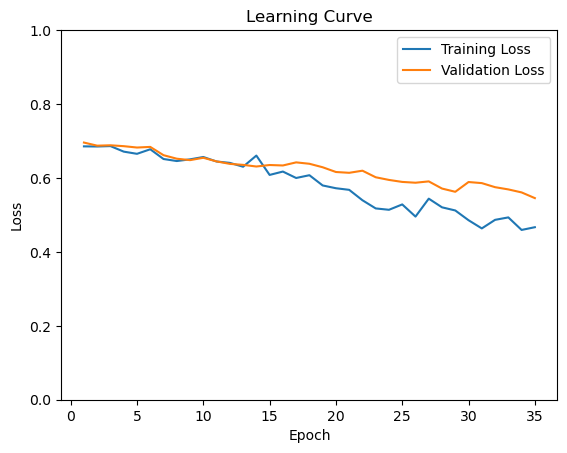

Fold 2
Accuracy Train: 0.7738775589028183. Accuracy valid: 0.7235714386616434
Recall Train: 0.6224490404129028. Recall valid: 0.5
Precision Train: 0.7391156554222107. Precision valid: 0.7666666669504983


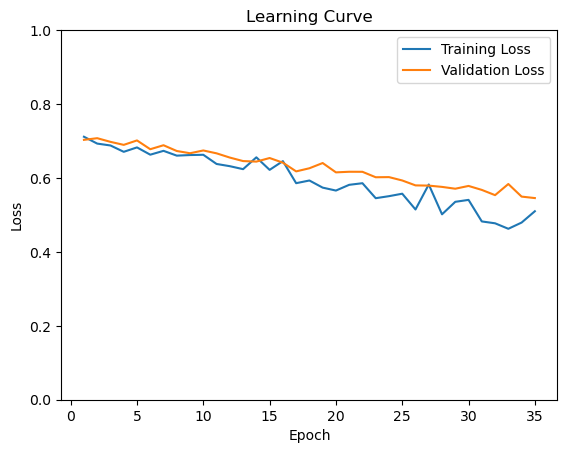

Fold 3
Accuracy Train: 0.803265313773739. Accuracy valid: 0.7850000006811959
Recall Train: 0.7131972908973694. Recall valid: 0.7809524536132812
Precision Train: 0.8591156601905823. Precision valid: 0.924761950969696


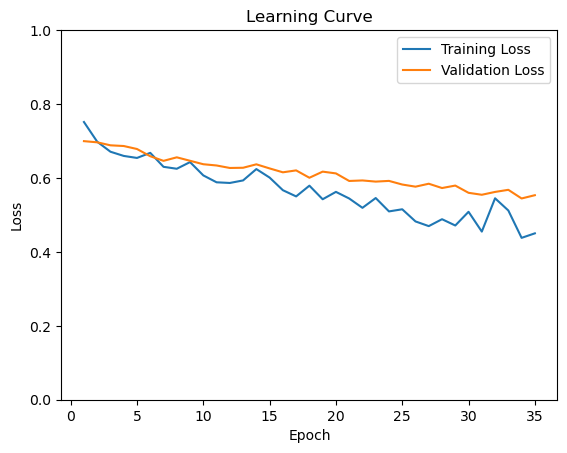

Fold 4
Accuracy Train: 0.7934693964160219. Accuracy valid: 0.613571435213089
Recall Train: 0.6387073993682861. Recall valid: 0.4285714030265808
Precision Train: 0.782312925372805. Precision valid: 0.34642857483455114


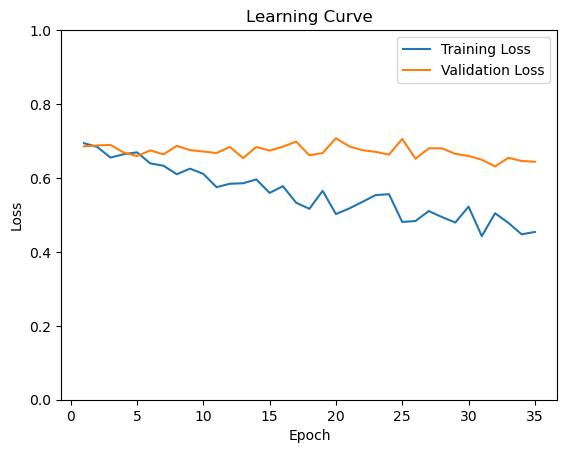

Fold 5
Accuracy Train: 0.7285714359155723. Accuracy valid: 0.7200000124318259
Recall Train: 0.5239286422729492. Recall valid: 0.6071428656578064
Precision Train: 0.6244643330574036. Precision valid: 0.6490476267678397


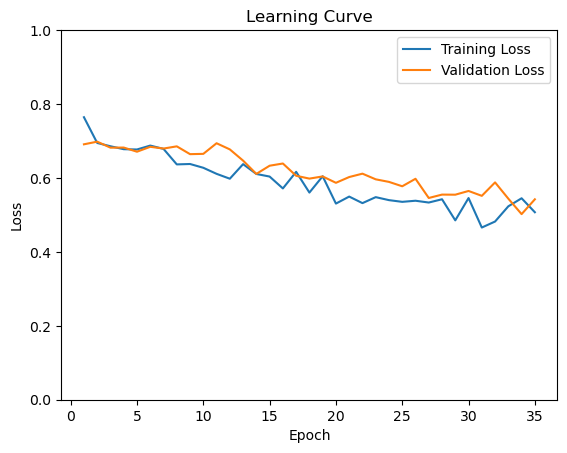

5
Fold 0: Training Loss: 0.5837414068835122, Validation Loss: 0.6240298484052931
Fold 1: Training Loss: 0.5945700722081321, Validation Loss: 0.6286266288587026
Fold 2: Training Loss: 0.5673011464732034, Validation Loss: 0.6147331718887602
Fold 3: Training Loss: 0.5583359846046992, Validation Loss: 0.6716521774019514
Fold 4: Training Loss: 0.5882006985800606, Validation Loss: 0.6178159356117249
TRAIN LOSS MEDIA: 0.5784298617499215 VALID LOSS MEDIA: 0.6313715524332864
TRAIN ACC MEDIA: 0.7775510280929049 VALID ACC MEDIA: 0.7118571504950524
TRAIN RECALL MEDIA: 0.633493185043335 VALID RECALL MEDIA: 0.5390475988388062
TRAIN PRECISION MEDIA: 0.7556684008666448 VALID PRECISION MEDIA: 0.6802381067616599


In [11]:
prueba_k_fold_resnet_no_pre(df_mean, 5, 35, optim.SGD , 5, 0.001, False, None)

Fold 1


Accuracy Train: 0.8522449035425576. Accuracy valid: 0.6485714358942849
Recall Train: 0.8312244415283203. Recall valid: 0.6714285612106323
Precision Train: 0.8515647053718567. Precision valid: 0.7376191020011902


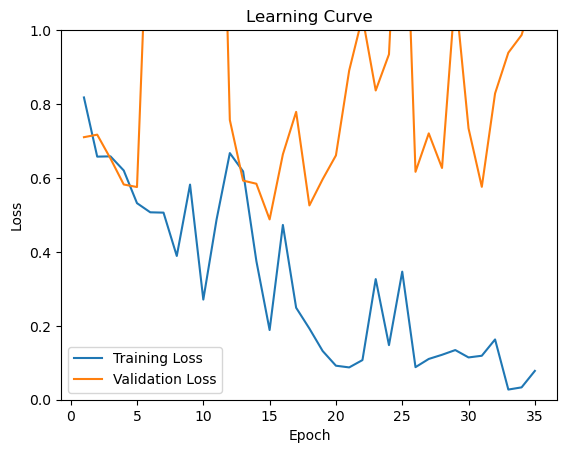

Fold 2
Accuracy Train: 0.8269387807164873. Accuracy valid: 0.7950000056198665
Recall Train: 0.7891836166381836. Recall valid: 0.9428571462631226
Precision Train: 0.8027210831642151. Precision valid: 0.8004761934280396


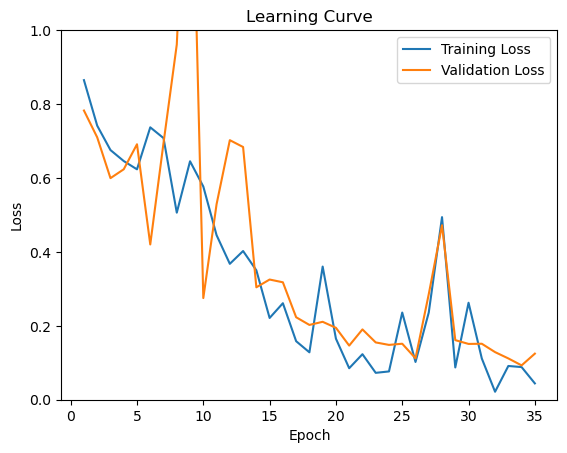

Fold 3
Accuracy Train: 0.8163265360253198. Accuracy valid: 0.7464285752602986
Recall Train: 0.7776870727539062. Recall valid: 0.80952388048172
Precision Train: 0.8002040982246399. Precision valid: 0.7711904772690364


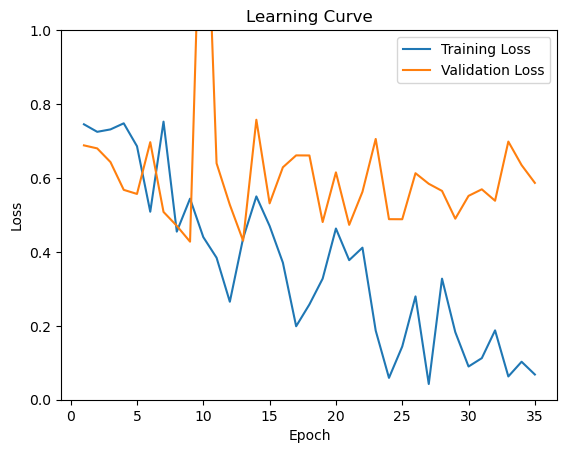

Fold 4
Accuracy Train: 0.8416326586081058. Accuracy valid: 0.7221428624221257
Recall Train: 0.8155782222747803. Recall valid: 0.8809523582458496
Precision Train: 0.8387754559516907. Precision valid: 0.6185714312962123


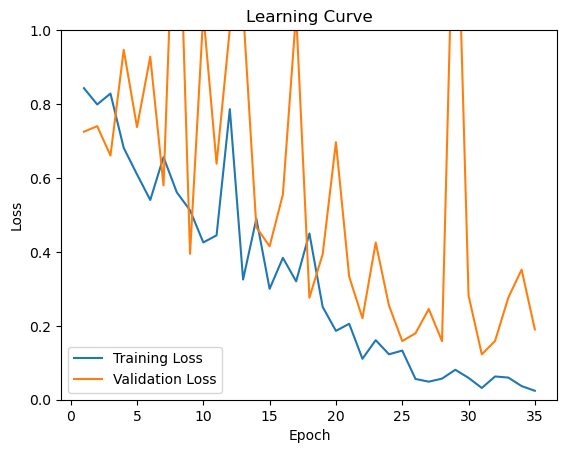

Fold 5
Accuracy Train: 0.7764285770377942. Accuracy valid: 0.6752381082092013
Recall Train: 0.6617857217788696. Recall valid: 0.6785714030265808
Precision Train: 0.6780357360839844. Precision valid: 0.6604762026241847


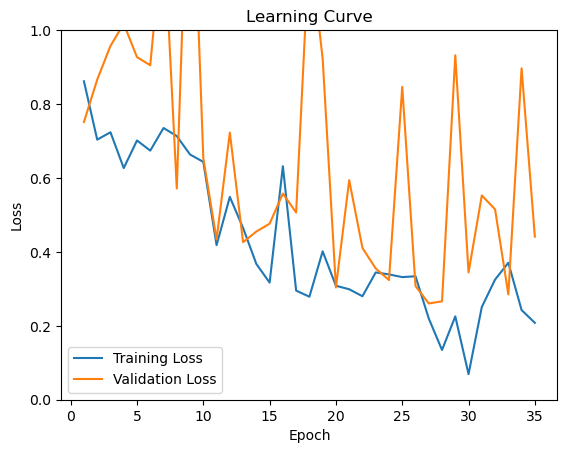

5
Fold 0: Training Loss: 0.31489127448626925, Validation Loss: 0.9366550015551703
Fold 1: Training Loss: 0.33473533354699614, Validation Loss: 0.39268038828990287
Fold 2: Training Loss: 0.36270331272057127, Validation Loss: 0.6104200057153191
Fold 3: Training Loss: 0.3327354679682425, Validation Loss: 0.5658666623490197
Fold 4: Training Loss: 0.4300622026835169, Validation Loss: 0.6554434744375093
TRAIN LOSS MEDIA: 0.35502551828111917 VALID LOSS MEDIA: 0.6322131064693843
TRAIN ACC MEDIA: 0.8227142911860529 VALID ACC MEDIA: 0.7174761974811553
TRAIN RECALL MEDIA: 0.775091826915741 VALID RECALL MEDIA: 0.79666668176651
TRAIN PRECISION MEDIA: 0.7942602038383484 VALID PRECISION MEDIA: 0.7176666813237327


In [12]:
prueba_k_fold_resnet_no_pre(df_mean, 5, 35, optim.SGD , 5, 0.01, False, None)

Fold 1
Accuracy Train: 0.7093877642738576. Accuracy valid: 0.5342857211828231
Recall Train: 0.8302040696144104. Recall valid: 0.5428571701049805
Precision Train: 0.7389115691184998. Precision valid: 0.36095237731933594


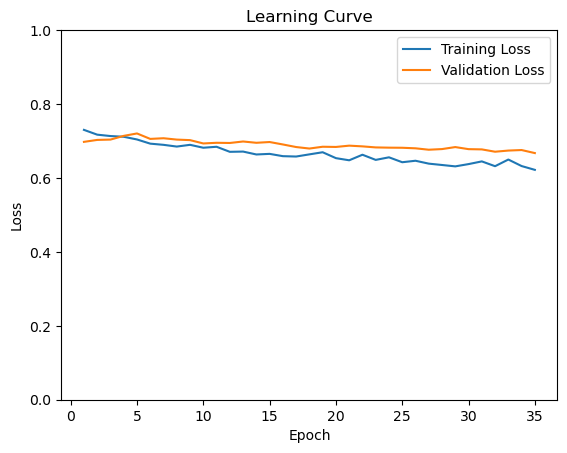

Fold 2
Accuracy Train: 0.5640816420316697. Accuracy valid: 0.5078571540968758
Recall Train: 0.9435374736785889. Recall valid: 0.9809523224830627
Precision Train: 0.552312970161438. Precision valid: 0.504047691822052


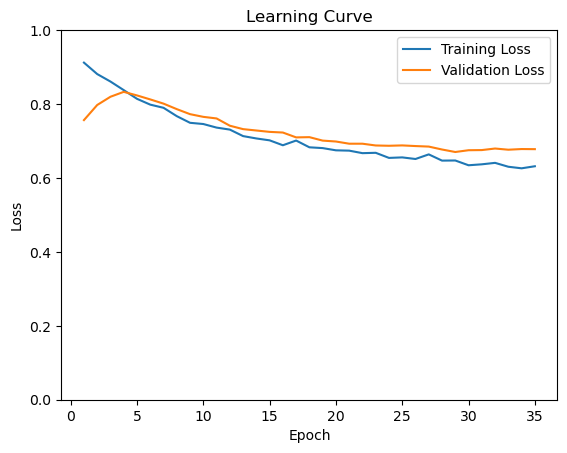

Fold 3
Accuracy Train: 0.5730612371649061. Accuracy valid: 0.5250000059604645
Recall Train: 0.08129251003265381. Recall valid: 0.0
Precision Train: 0.1469387799501419. Precision valid: 0.0


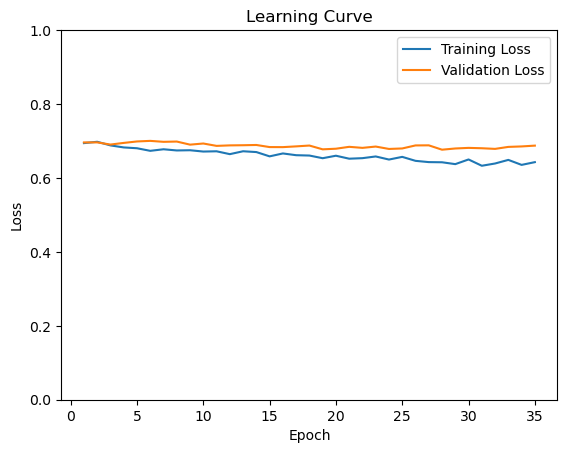

Fold 4
Accuracy Train: 0.6081632768013039. Accuracy valid: 0.6092857186283384
Recall Train: 0.17142857611179352. Recall valid: 0.05714285746216774
Precision Train: 0.3224489986896515. Precision valid: 0.11428571428571428


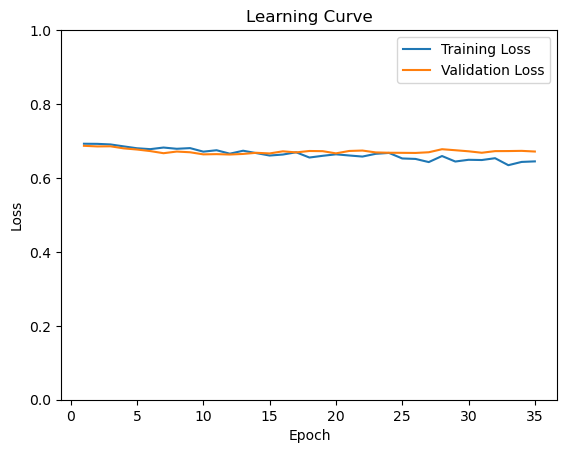

Fold 5
Accuracy Train: 0.6564285809440272. Accuracy valid: 0.296190482378006
Recall Train: 0.6651785969734192. Recall valid: 0.34285715222358704
Precision Train: 0.6324405074119568. Precision valid: 0.1961904764175415


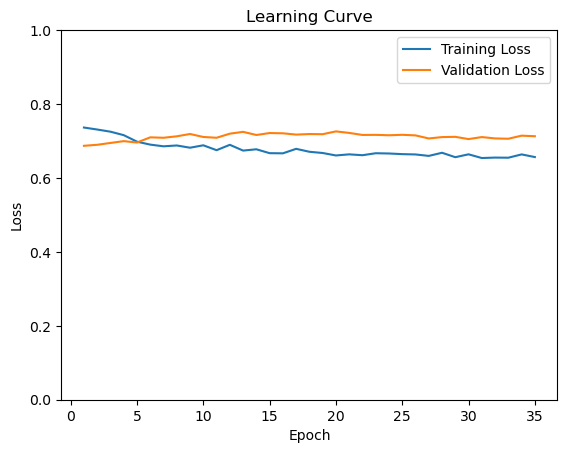

5
Fold 0: Training Loss: 0.6657788021223886, Validation Loss: 0.6895843471799578
Fold 1: Training Loss: 0.7114948885781425, Validation Loss: 0.7265068897179194
Fold 2: Training Loss: 0.6612523181097848, Validation Loss: 0.6869892452444349
Fold 3: Training Loss: 0.6646748355456761, Validation Loss: 0.6718097056661333
Fold 4: Training Loss: 0.6767916219575064, Validation Loss: 0.7116634547710419
TRAIN LOSS MEDIA: 0.6759984932626997 VALID LOSS MEDIA: 0.6973107285158975
TRAIN ACC MEDIA: 0.6222245002431529 VALID ACC MEDIA: 0.49452381644930166
TRAIN RECALL MEDIA: 0.538328230381012 VALID RECALL MEDIA: 0.38476186990737915
TRAIN PRECISION MEDIA: 0.4786105650663376 VALID PRECISION MEDIA: 0.23509525196892875


In [13]:
prueba_k_fold_resnet_no_pre(df_mean, 5, 35, optim.SGD , 5, 0.0001, False, None)

### PRUEBAS BS

Fold 1
Accuracy Train: 0.7503968317593847. Accuracy valid: 0.7333333466734205
Recall Train: 0.565079391002655. Recall valid: 0.4809524118900299
Precision Train: 0.6242063045501709. Precision valid: 0.5730158882481712


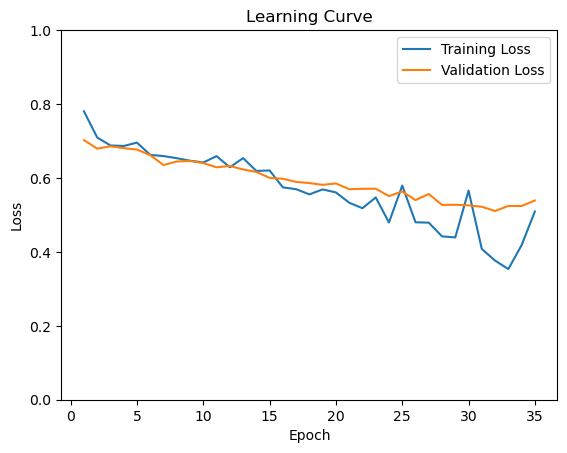

Fold 2
Accuracy Train: 0.7753968316884268. Accuracy valid: 0.8253968341009957
Recall Train: 0.559920608997345. Recall valid: 0.5904761552810669
Precision Train: 0.6222222185560635. Precision valid: 0.5761904903820583


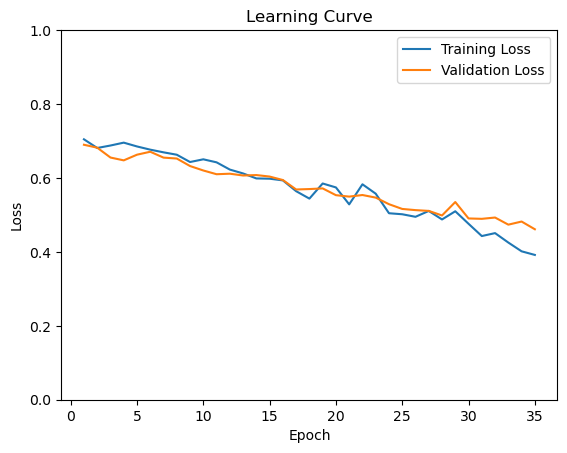

Fold 3
Accuracy Train: 0.7099206428442681. Accuracy valid: 0.8190476278464001
Recall Train: 0.4920635223388672. Recall valid: 0.5476190447807312
Precision Train: 0.5718253254890442. Precision valid: 0.5571428733212608


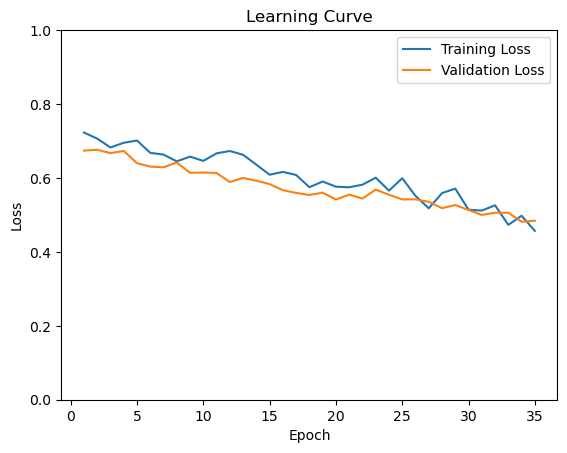

Fold 4
Accuracy Train: 0.72738096061207. Accuracy valid: 0.6222222336700983
Recall Train: 0.5440476536750793. Recall valid: 0.6714285016059875
Precision Train: 0.6158730387687683. Precision valid: 0.4634920780147825


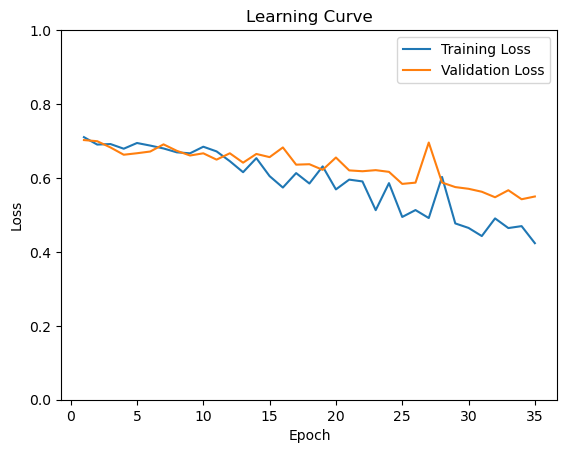

Fold 5
Accuracy Train: 0.7166666753944896. Accuracy valid: 0.5460317540736425
Recall Train: 0.4396825432777405. Recall valid: 0.27619045972824097
Precision Train: 0.5313492077269725. Precision valid: 0.24761904648372104


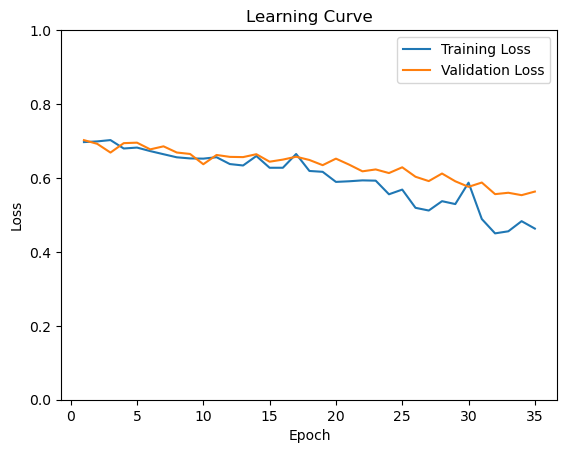

5
Fold 0: Training Loss: 0.5703774086066655, Validation Loss: 0.5947494438716343
Fold 1: Training Loss: 0.5702402719429561, Validation Loss: 0.5745540718237557
Fold 2: Training Loss: 0.6029461605208261, Validation Loss: 0.574275078659966
Fold 3: Training Loss: 0.5896624556609562, Validation Loss: 0.632468200865246
Fold 4: Training Loss: 0.600500772680555, Validation Loss: 0.6350641091664633
TRAIN LOSS MEDIA: 0.5867454138823918 VALID LOSS MEDIA: 0.6022221808774131
TRAIN ACC MEDIA: 0.7359523884597279 VALID ACC MEDIA: 0.7092063592729114
TRAIN RECALL MEDIA: 0.5201587080955505 VALID RECALL MEDIA: 0.5133333206176758
TRAIN PRECISION MEDIA: 0.593095219018204 VALID PRECISION MEDIA: 0.4834920752899988


In [14]:
prueba_k_fold_resnet_no_pre(df_mean, 5, 35, optim.SGD , 3, 0.001, False, None)

Fold 1
Accuracy Train: 0.7500000020435879. Accuracy valid: 0.4035714285714286
Recall Train: 0.47676196694374084. Recall valid: 0.17142856121063232
Precision Train: 0.6561904792274748. Precision valid: 0.38571428571428573


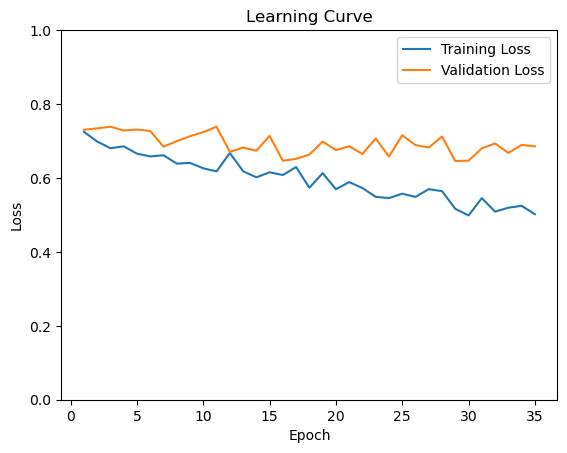

Fold 2
Accuracy Train: 0.781904762983322. Accuracy valid: 0.6
Recall Train: 0.6350204348564148. Recall valid: 0.3809523582458496
Precision Train: 0.7553333388907569. Precision valid: 0.5585714289120265


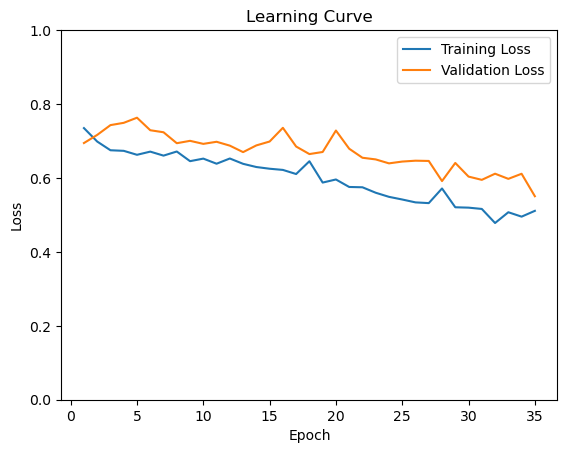

Fold 3
Accuracy Train: 0.7576190492085049. Accuracy valid: 0.8089285714285714
Recall Train: 0.5124489665031433. Recall valid: 0.6857143640518188
Precision Train: 0.6895238161087036. Precision valid: 0.7596938780375889


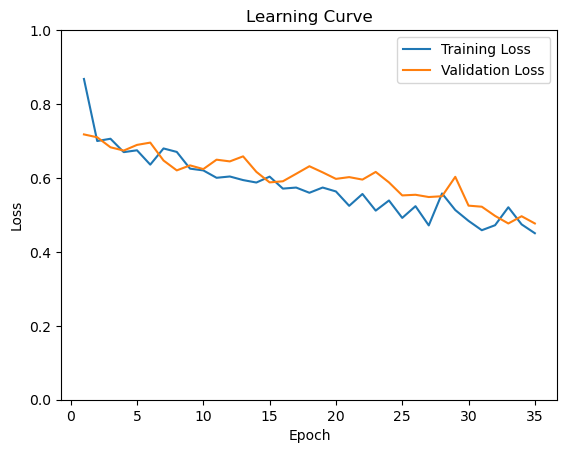

Fold 4
Accuracy Train: 0.7750000017029899. Accuracy valid: 0.7053571428571429
Recall Train: 0.644095242023468. Recall valid: 0.21071428060531616
Precision Train: 0.7988570928573608. Precision valid: 0.23619047914232527


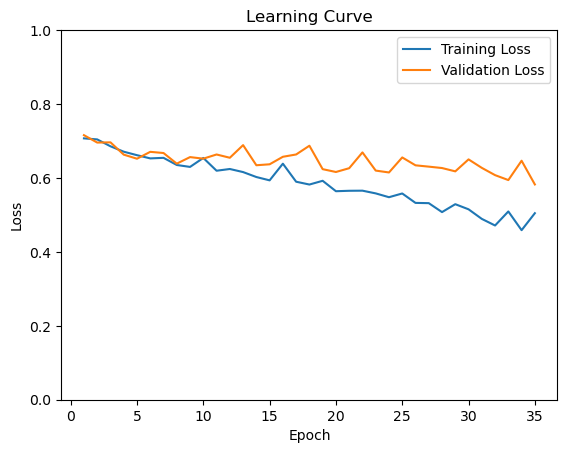

Fold 5
Accuracy Train: 0.79. Accuracy valid: 0.5714285714285714
Recall Train: 0.728095293045044. Recall valid: 0.30714285373687744
Precision Train: 0.8113265633583069. Precision valid: 0.6380952400820595


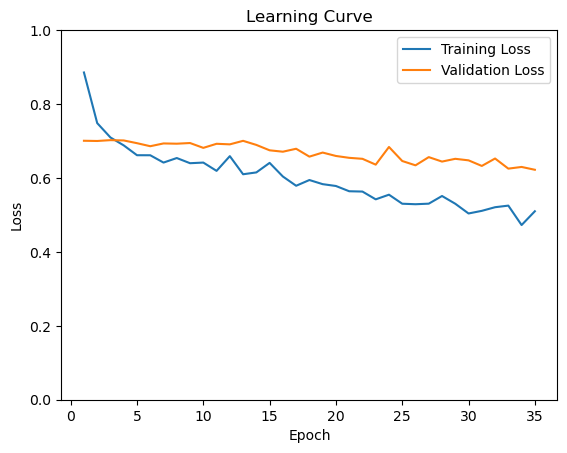

5
Fold 0: Training Loss: 0.5973263340336936, Validation Loss: 0.6928156861237117
Fold 1: Training Loss: 0.599353973354612, Validation Loss: 0.6712592133453914
Fold 2: Training Loss: 0.5781155288219452, Validation Loss: 0.6030367131744112
Fold 3: Training Loss: 0.586403432062694, Validation Loss: 0.6468301917825426
Fold 4: Training Loss: 0.5986591730798994, Validation Loss: 0.6685559596334185
TRAIN LOSS MEDIA: 0.5919716882705688 VALID LOSS MEDIA: 0.6564995528118951
TRAIN ACC MEDIA: 0.7709047631876809 VALID ACC MEDIA: 0.6178571428571429
TRAIN RECALL MEDIA: 0.5992843508720398 VALID RECALL MEDIA: 0.3511905074119568
TRAIN PRECISION MEDIA: 0.7422462580885206 VALID PRECISION MEDIA: 0.5156530623776572


In [15]:
prueba_k_fold_resnet_no_pre(df_mean, 5, 35, optim.SGD , 8, 0.001, False, None)

## SGD DATA AUG

Fold 1
Accuracy Train: 0.6840816435765247. Accuracy valid: 0.6571428648063115
Recall Train: 0.4799319803714752. Recall valid: 0.3571428656578064
Precision Train: 0.6208843518580709. Precision valid: 0.5590476206370762


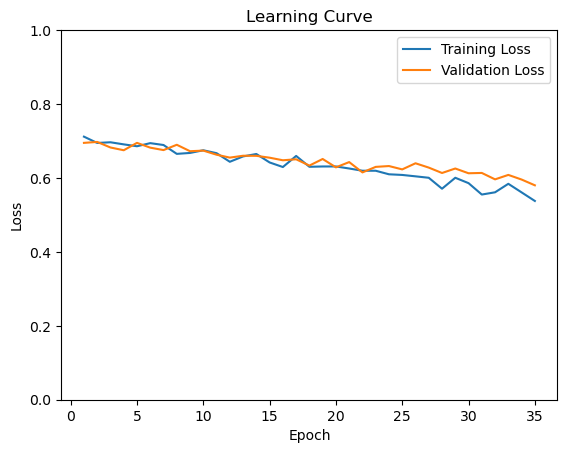

Fold 2
Accuracy Train: 0.6816326641306585. Accuracy valid: 0.7364285775593349
Recall Train: 0.373129278421402. Recall valid: 0.41904762387275696
Precision Train: 0.5278911628893443. Precision valid: 0.5571428571428572


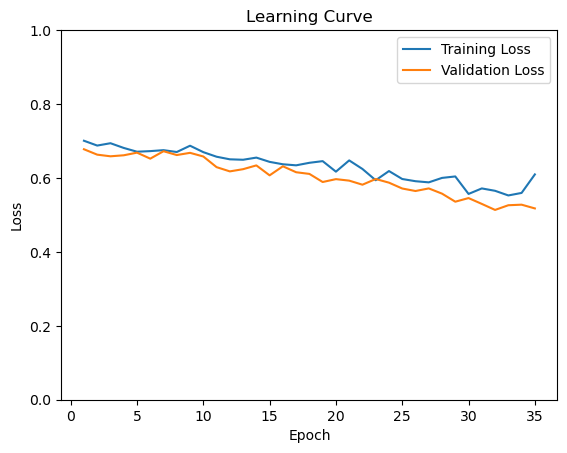

Fold 3
Accuracy Train: 0.6791836848672556. Accuracy valid: 0.7592857171382222
Recall Train: 0.4953741431236267. Recall valid: 0.6952381730079651
Precision Train: 0.6402720808982849. Precision valid: 0.7311904770987374


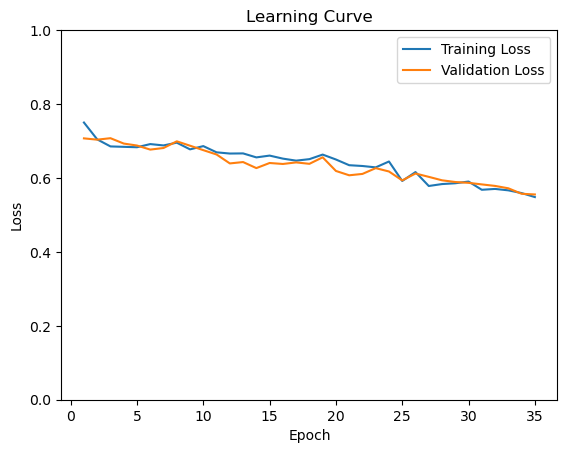

Fold 4
Accuracy Train: 0.7330612346834067. Accuracy valid: 0.6964285769632884
Recall Train: 0.5296599268913269. Recall valid: 0.4571428596973419
Precision Train: 0.7229251759392875. Precision valid: 0.4300000011920929


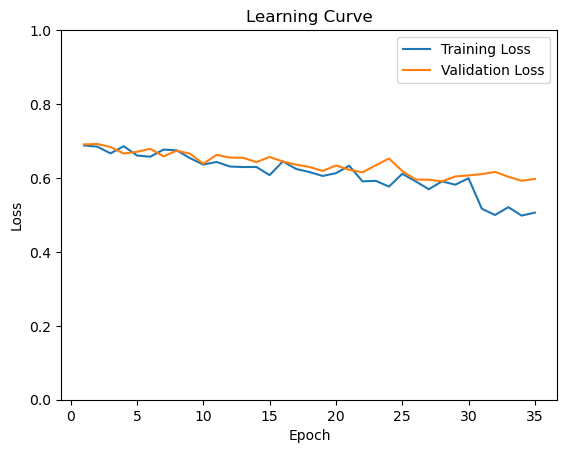

Fold 5
Accuracy Train: 0.6771428667541061. Accuracy valid: 0.5695238258157458
Recall Train: 0.3898809850215912. Recall valid: 0.30714285373687744
Precision Train: 0.516190476502691. Precision valid: 0.39476190975734166


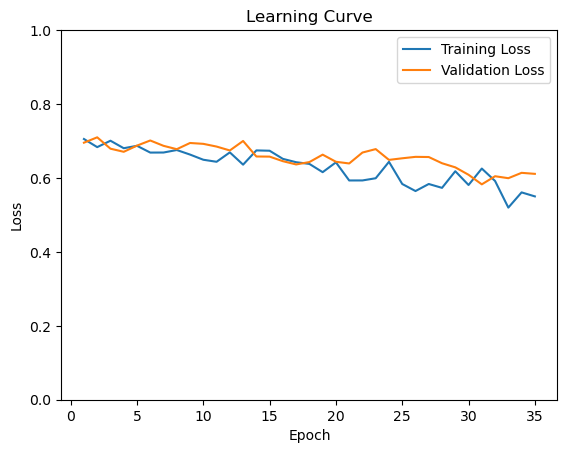

5
Fold 0: Training Loss: 0.633507900578635, Validation Loss: 0.6457133233547211
Fold 1: Training Loss: 0.6320296236446925, Validation Loss: 0.6033809853451593
Fold 2: Training Loss: 0.6407144444329398, Validation Loss: 0.6345860864434923
Fold 3: Training Loss: 0.611661559343338, Validation Loss: 0.6374222678797585
Fold 4: Training Loss: 0.6300623536109924, Validation Loss: 0.6569735748427254
TRAIN LOSS MEDIA: 0.6295951763221195 VALID LOSS MEDIA: 0.6356152475731713
TRAIN ACC MEDIA: 0.6910204188023903 VALID ACC MEDIA: 0.6837619124565806
TRAIN RECALL MEDIA: 0.45359525084495544 VALID RECALL MEDIA: 0.44714289903640747
TRAIN PRECISION MEDIA: 0.6056326496175357 VALID PRECISION MEDIA: 0.5344285731656211


In [16]:
prueba_k_fold_resnet_no_pre(df_mean, 5, 35, optim.SGD , 5, 0.001, True, None)

Fold 1
Accuracy Train: 0.8720000060115541. Accuracy valid: 0.7560000067949295
Recall Train: 0.7780476212501526. Recall valid: 0.46000000834465027
Precision Train: 0.8776190477609634. Precision valid: 0.885


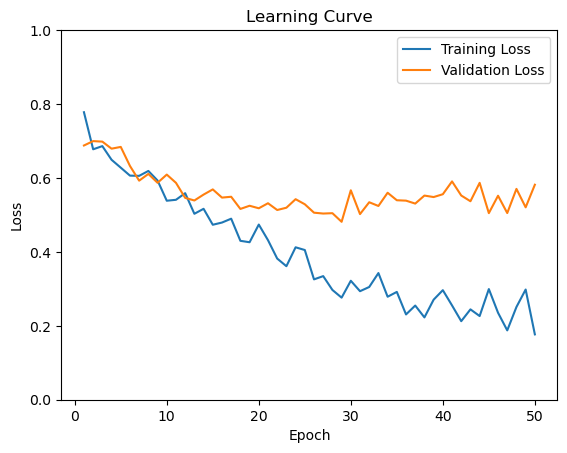

Fold 2
Accuracy Train: 0.8531428639803614. Accuracy valid: 0.8035000059008598
Recall Train: 0.7393333315849304. Recall valid: 0.7033332586288452
Precision Train: 0.8566666668653489. Precision valid: 0.7716666674613952


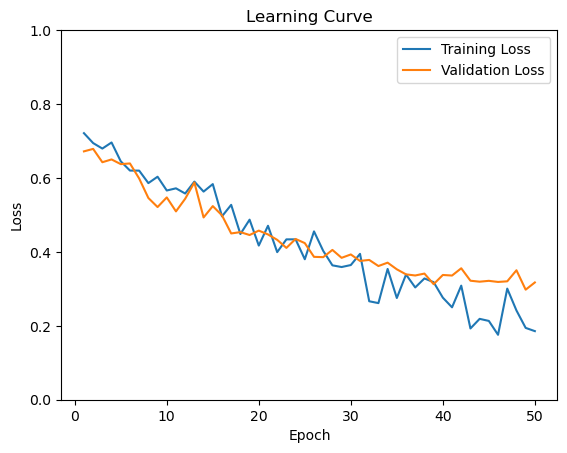

Fold 3
Accuracy Train: 0.8331428643635341. Accuracy valid: 0.7810000030696392
Recall Train: 0.7432856559753418. Recall valid: 0.7533332705497742
Precision Train: 0.8269046545028687. Precision valid: 0.7886666691303253


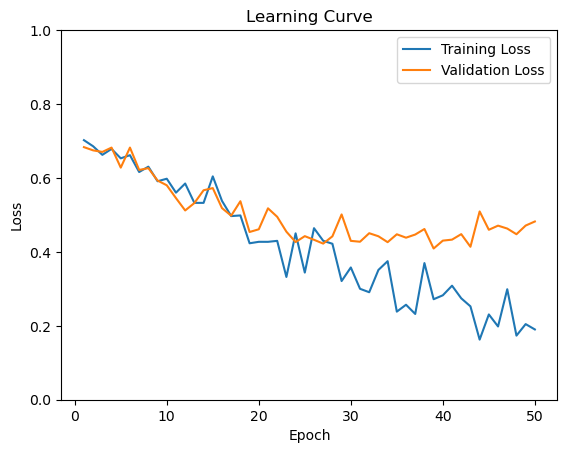

Fold 4
Accuracy Train: 0.8588571492263248. Accuracy valid: 0.7320000070333481
Recall Train: 0.8416666984558105. Recall valid: 0.8566667437553406
Precision Train: 0.8955238461494446. Precision valid: 0.5713332891464233


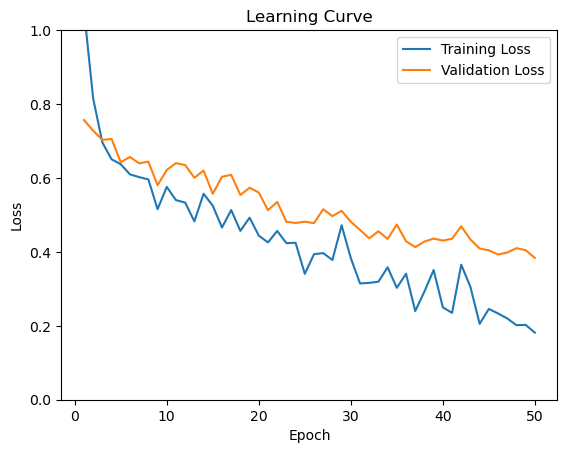

Fold 5
Accuracy Train: 0.7505000078305603. Accuracy valid: 0.7260000118613243
Recall Train: 0.5747500061988831. Recall valid: 0.7049999833106995
Precision Train: 0.6992083787918091. Precision valid: 0.706333349943161


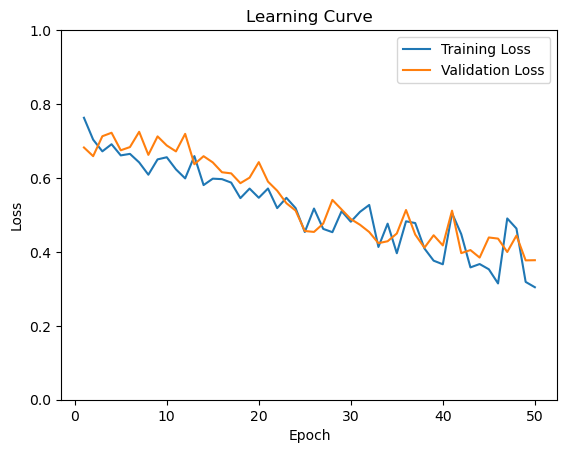

5
Fold 0: Training Loss: 0.3998852455615997, Validation Loss: 0.5603701314330101
Fold 1: Training Loss: 0.4226915231347084, Validation Loss: 0.43930282413959504
Fold 2: Training Loss: 0.41838312238454817, Validation Loss: 0.5037022667378187
Fold 3: Training Loss: 0.4267922866344452, Validation Loss: 0.5228102043271065
Fold 4: Training Loss: 0.520193157196045, Validation Loss: 0.5414725969731807
TRAIN LOSS MEDIA: 0.43758906698226935 VALID LOSS MEDIA: 0.5135316047221423
TRAIN ACC MEDIA: 0.833528578282467 VALID ACC MEDIA: 0.7597000069320202
TRAIN RECALL MEDIA: 0.7354166507720947 VALID RECALL MEDIA: 0.6956666707992554
TRAIN PRECISION MEDIA: 0.8311845188140868 VALID PRECISION MEDIA: 0.744599995136261


In [17]:
prueba_k_fold_resnet_no_pre(df_mean, 5, 50, optim.SGD , 5, 0.001, True, 'G')


Fold 1
Accuracy Train: 0.8057142935237106. Accuracy valid: 0.7178571509463446
Recall Train: 0.6710203886032104. Recall valid: 0.48571428656578064
Precision Train: 0.752380953516279. Precision valid: 0.7285714319774083


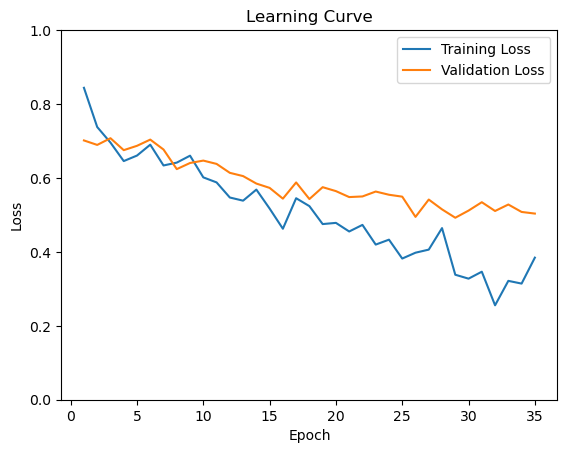

Fold 2
Accuracy Train: 0.7893877633980342. Accuracy valid: 0.820000006045614
Recall Train: 0.6817687153816223. Recall valid: 0.6476190686225891
Precision Train: 0.8149660229682922. Precision valid: 0.784761905670166


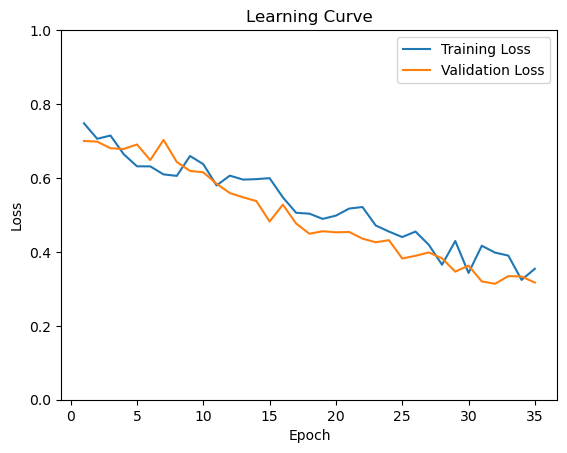

Fold 3
Accuracy Train: 0.8440816389662879. Accuracy valid: 0.8328571447304317
Recall Train: 0.8506122827529907. Recall valid: 0.7761905789375305
Precision Train: 0.8691156506538391. Precision valid: 0.8904761910438538


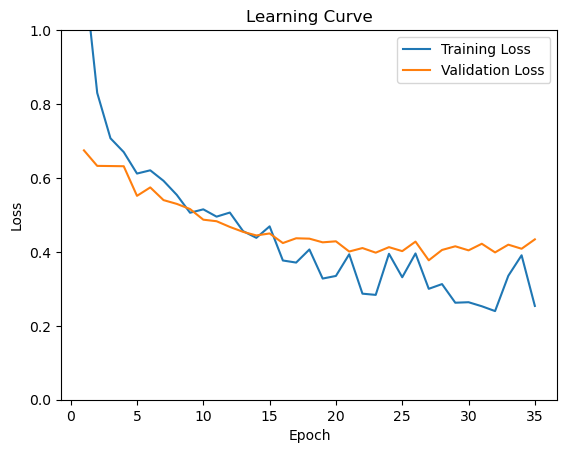

Fold 4
Accuracy Train: 0.7714285821939002. Accuracy valid: 0.6092857224600655
Recall Train: 0.7210884690284729. Recall valid: 0.8761904835700989
Precision Train: 0.8194558024406433. Precision valid: 0.49071425199508667


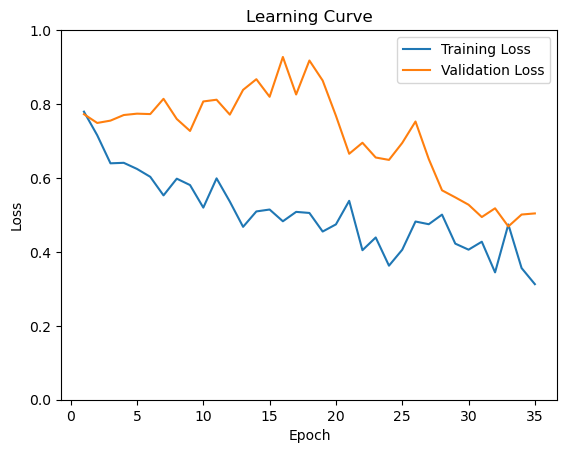

Fold 5
Accuracy Train: 0.7614285795816353. Accuracy valid: 0.7857142946549824
Recall Train: 0.589226245880127. Recall valid: 0.7357142567634583
Precision Train: 0.7311905026435852. Precision valid: 0.7428571564810617


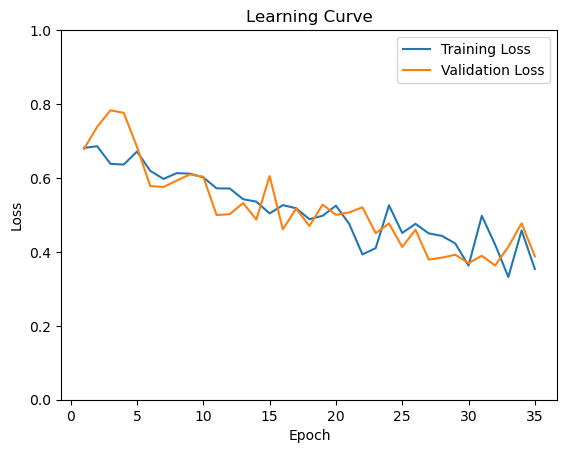

5
Fold 0: Training Loss: 0.5078469370092664, Validation Loss: 0.5853721520730427
Fold 1: Training Loss: 0.5265626404966627, Validation Loss: 0.4965134254523686
Fold 2: Training Loss: 0.4472389872585024, Validation Loss: 0.46732020995446616
Fold 3: Training Loss: 0.5045296856335231, Validation Loss: 0.714404559986932
Fold 4: Training Loss: 0.5174303472042083, Validation Loss: 0.5173865173544202
TRAIN LOSS MEDIA: 0.5007217195204327 VALID LOSS MEDIA: 0.5561993729642459
TRAIN ACC MEDIA: 0.7944081715327137 VALID ACC MEDIA: 0.7531428637674876
TRAIN RECALL MEDIA: 0.7027432322502136 VALID RECALL MEDIA: 0.704285740852356
TRAIN PRECISION MEDIA: 0.7974217864445278 VALID PRECISION MEDIA: 0.7274761874335153


In [18]:
prueba_k_fold_resnet_no_pre(df_mean, 5, 35, optim.SGD , 5, 0.001, True, 'H')

## RMSProp NO AUG

### PRUEBAS LR

Fold 1
Accuracy Train: 0.8285714359915987. Accuracy valid: 0.6400000078337533
Recall Train: 0.8225169777870178. Recall valid: 0.4714285731315613
Precision Train: 0.8401360511779785. Precision valid: 0.5933333354336875


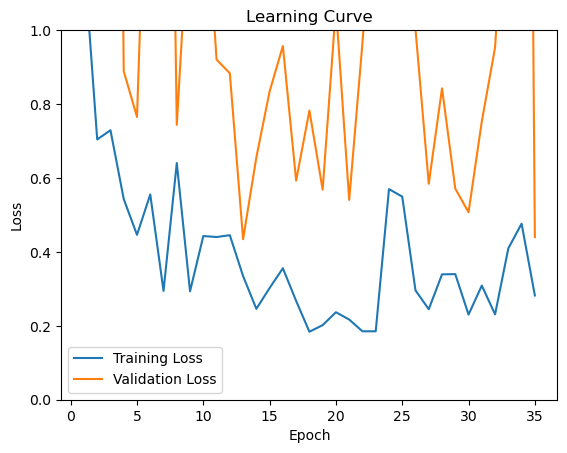

Fold 2
Accuracy Train: 0.8138775587081909. Accuracy valid: 0.8042857195649828
Recall Train: 0.7897958755493164. Recall valid: 0.6666666865348816
Precision Train: 0.8176870942115784. Precision valid: 0.7261904767581395


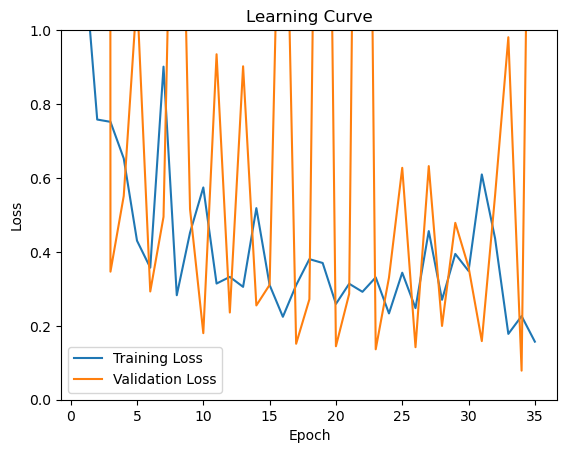

Fold 3
Accuracy Train: 0.8432653126667956. Accuracy valid: 0.7514285738979067
Recall Train: 0.7874829173088074. Recall valid: 0.7380952835083008
Precision Train: 0.8582313060760498. Precision valid: 0.7578571438789368


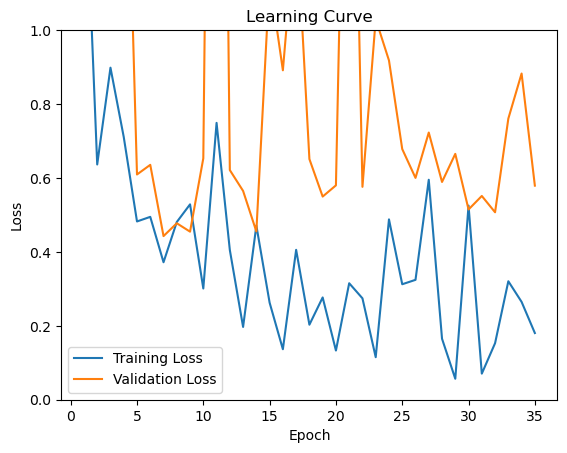

Fold 4
Accuracy Train: 0.8244898044333165. Accuracy valid: 0.7085714344467435
Recall Train: 0.767346978187561. Recall valid: 0.747619092464447
Precision Train: 0.8589115738868713. Precision valid: 0.5664285753454481


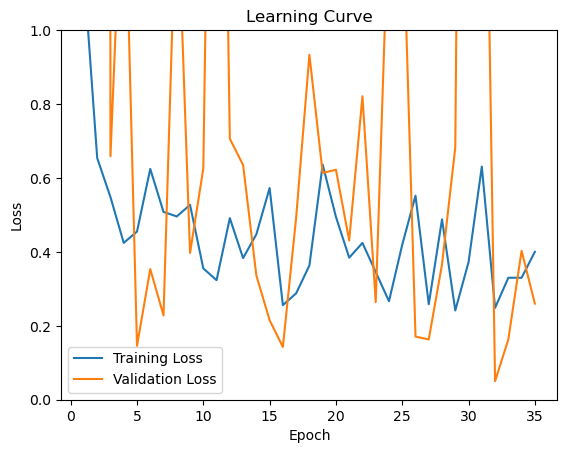

Fold 5
Accuracy Train: 0.7971428642315525. Accuracy valid: 0.690476204242025
Recall Train: 0.6880357265472412. Recall valid: 0.7714285850524902
Precision Train: 0.7174999713897705. Precision valid: 0.6600000177110944


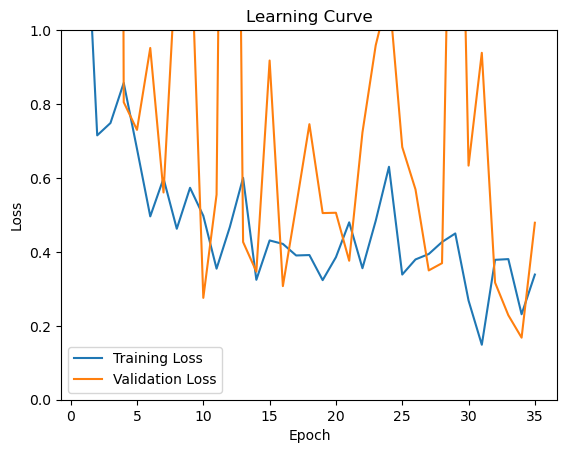

5
Fold 0: Training Loss: 0.39222049968583245, Validation Loss: 861.2033517132912
Fold 1: Training Loss: 0.41505761742591857, Validation Loss: 7.314248053529965
Fold 2: Training Loss: 0.39513919864382063, Validation Loss: 14.965426561768567
Fold 3: Training Loss: 0.44844977983406614, Validation Loss: 6.968036173975894
Fold 4: Training Loss: 0.48153305522033146, Validation Loss: 4.75411770861995
TRAIN LOSS MEDIA: 0.4264800301619938 VALID LOSS MEDIA: 179.0410360422371
TRAIN ACC MEDIA: 0.8214693952062909 VALID ACC MEDIA: 0.7189523879970823
TRAIN RECALL MEDIA: 0.7710357308387756 VALID RECALL MEDIA: 0.6790476441383362
TRAIN PRECISION MEDIA: 0.8184931874275208 VALID PRECISION MEDIA: 0.6607619098254612


In [19]:
prueba_k_fold_resnet_no_pre(df_mean, 5, 35, optim.RMSprop , 5, 0.001, False, None)

Fold 1
Accuracy Train: 0.9591836753548408. Accuracy valid: 0.7350000070674079
Recall Train: 0.9362584948539734. Recall valid: 0.4714285731315613
Precision Train: 0.936734676361084. Precision valid: 0.8628571425165449


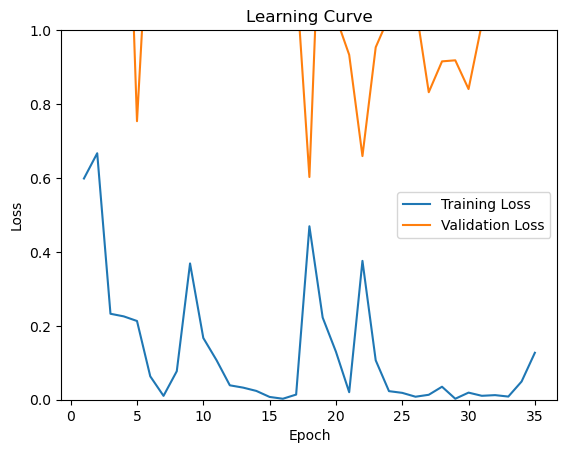

Fold 2
Accuracy Train: 0.9355102070132079. Accuracy valid: 0.8707142910787038
Recall Train: 0.9293197393417358. Recall valid: 0.8476190567016602
Precision Train: 0.9196598529815674. Precision valid: 0.9207142863954817


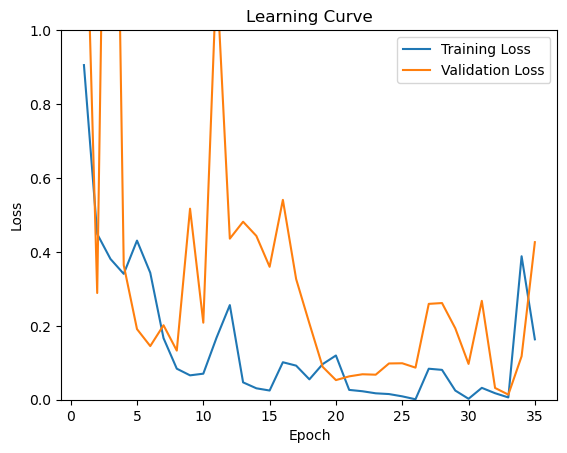

Fold 3
Accuracy Train: 0.9379591863374321. Accuracy valid: 0.8092857156481061
Recall Train: 0.8961225152015686. Recall valid: 0.8190476298332214
Precision Train: 0.9113606214523315. Precision valid: 0.8938095246042524


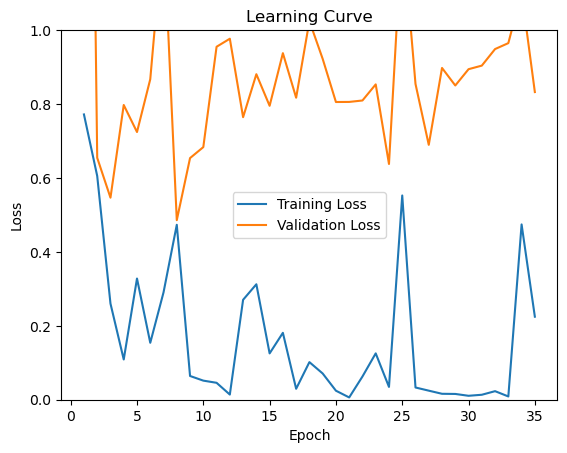

Fold 4
Accuracy Train: 0.922448982754532. Accuracy valid: 0.7921428603785379
Recall Train: 0.8962584733963013. Recall valid: 0.9333332777023315
Precision Train: 0.915238082408905. Precision valid: 0.6788095831871033


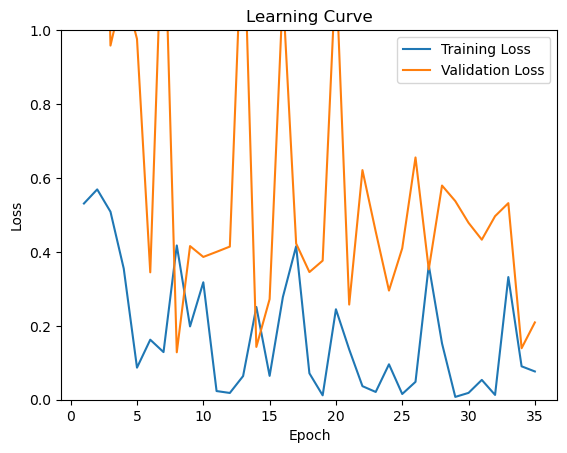

Fold 5
Accuracy Train: 0.9164285743875163. Accuracy valid: 0.7800000097070422
Recall Train: 0.8063095211982727. Recall valid: 0.8571428656578064
Precision Train: 0.8143452405929565. Precision valid: 0.783809540952955


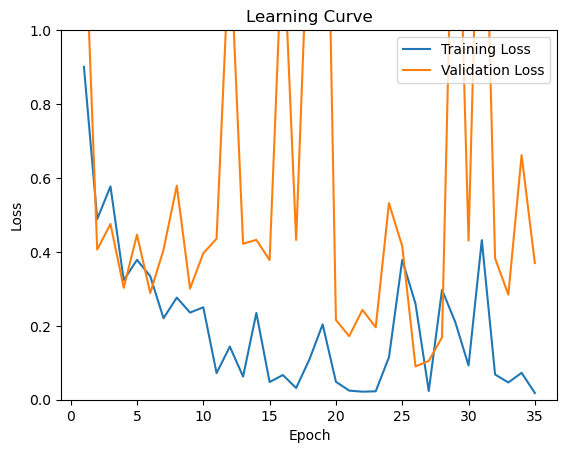

5
Fold 0: Training Loss: 0.12862685398597803, Validation Loss: 1.2516552520649773
Fold 1: Training Loss: 0.14628626466728747, Validation Loss: 0.3584191218783547
Fold 2: Training Loss: 0.16883369142721807, Validation Loss: 0.9247950683680496
Fold 3: Training Loss: 0.17653032490717513, Validation Loss: 0.645601086824068
Fold 4: Training Loss: 0.202560967579484, Validation Loss: 0.5978456081689468
TRAIN LOSS MEDIA: 0.16456762051342855 VALID LOSS MEDIA: 0.7556632274608792
TRAIN ACC MEDIA: 0.9343061251695058 VALID ACC MEDIA: 0.7974285767759596
TRAIN RECALL MEDIA: 0.8928537368774414 VALID RECALL MEDIA: 0.785714328289032
TRAIN PRECISION MEDIA: 0.8994676470756531 VALID PRECISION MEDIA: 0.8280000155312675


In [20]:
prueba_k_fold_resnet_no_pre(df_mean, 5, 35, optim.RMSprop , 5, 0.0001, False, None)

Fold 1
Accuracy Train: 0.9616326547398858. Accuracy valid: 0.7085714374269758
Recall Train: 0.9178911447525024. Recall valid: 0.4214285612106323
Precision Train: 0.9408164024353027. Precision valid: 0.7642857142857142


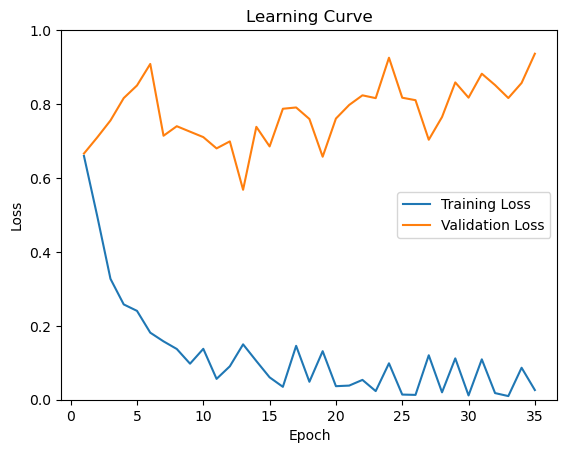

Fold 2
Accuracy Train: 0.9632653074605124. Accuracy valid: 0.8692857201610292
Recall Train: 0.9204761981964111. Recall valid: 0.7571429014205933
Precision Train: 0.9469387531280518. Precision valid: 0.9142857142857143


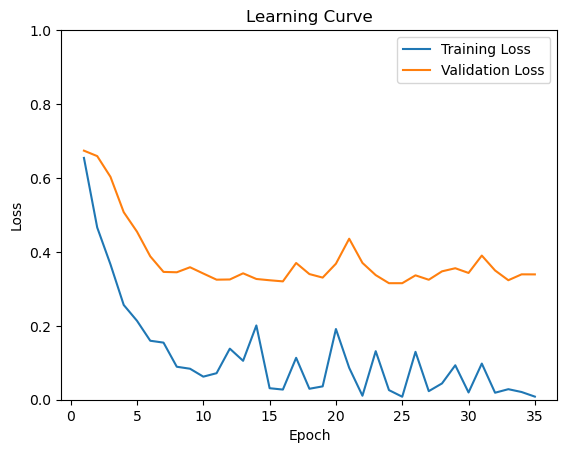

Fold 3
Accuracy Train: 0.9722448993702325. Accuracy valid: 0.8421428578240531
Recall Train: 0.946258544921875. Recall valid: 0.7476191520690918
Precision Train: 0.956462562084198. Precision valid: 0.9


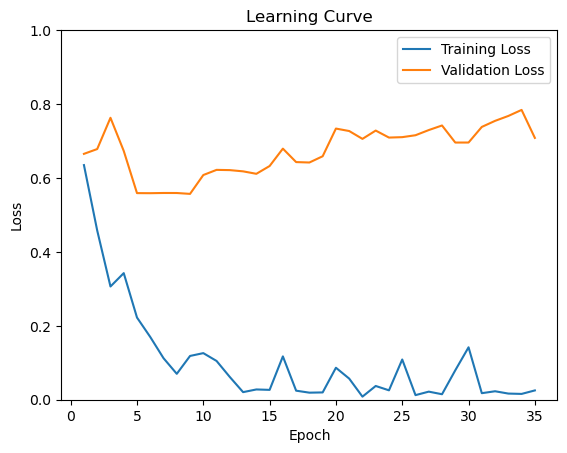

Fold 4
Accuracy Train: 0.9706122461630374. Accuracy valid: 0.8185714312962123
Recall Train: 0.9577550888061523. Recall valid: 1.0
Precision Train: 0.9606803059577942. Precision valid: 0.7200000286102295


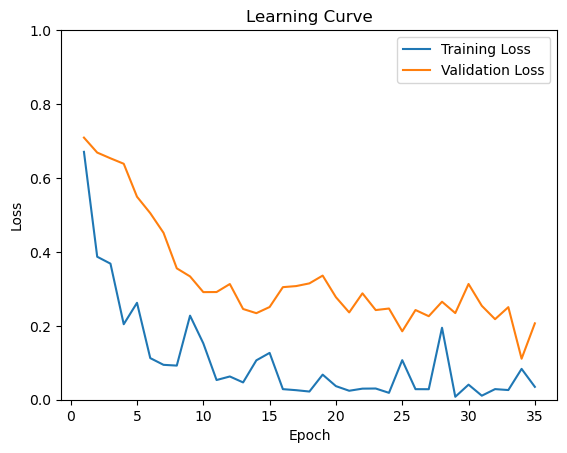

Fold 5
Accuracy Train: 0.9421428580901452. Accuracy valid: 0.8333333428416934
Recall Train: 0.8430356979370117. Recall valid: 0.7857142686843872
Precision Train: 0.8559523224830627. Precision valid: 0.974761962890625


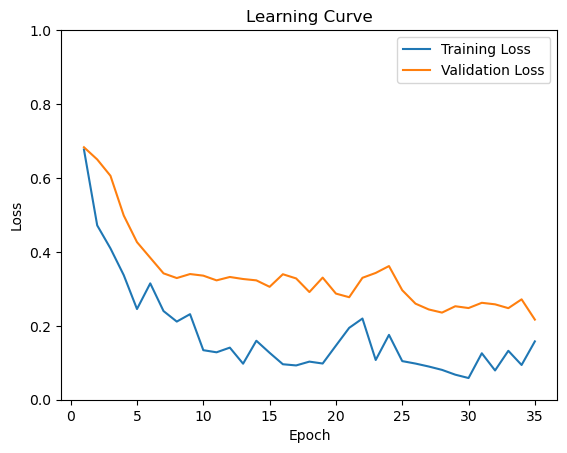

5
Fold 0: Training Loss: 0.12306099440902471, Validation Loss: 0.7771232451711382
Fold 1: Training Loss: 0.11993364627872194, Validation Loss: 0.3791219774101462
Fold 2: Training Loss: 0.1049895860786949, Validation Loss: 0.6729768956878356
Fold 3: Training Loss: 0.1098197336175612, Validation Loss: 0.3300060016768319
Fold 4: Training Loss: 0.178486376787935, Validation Loss: 0.33962267147643227
TRAIN LOSS MEDIA: 0.12725806743438756 VALID LOSS MEDIA: 0.4997701582844768
TRAIN ACC MEDIA: 0.9619795931647627 VALID ACC MEDIA: 0.8143809579099928
TRAIN RECALL MEDIA: 0.9170833826065063 VALID RECALL MEDIA: 0.7423809766769409
TRAIN PRECISION MEDIA: 0.9321700930595398 VALID PRECISION MEDIA: 0.8546666840144566


In [21]:
prueba_k_fold_resnet_no_pre(df_mean, 5, 35, optim.RMSprop , 5, 0.00001, False, None)

### PRUEBAS BS

Fold 1
Accuracy Train: 0.9242063518790973. Accuracy valid: 0.7587301725432987
Recall Train: 0.759920597076416. Recall valid: 0.4523809850215912
Precision Train: 0.8011904358863831. Precision valid: 0.6095238276890346


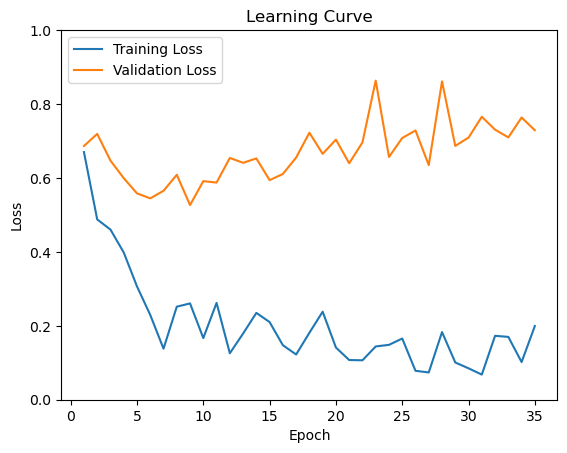

Fold 2
Accuracy Train: 0.9285714311968712. Accuracy valid: 0.8825396881217049
Recall Train: 0.8103174567222595. Recall valid: 0.8285714387893677
Precision Train: 0.8416667580604553. Precision valid: 0.7746031752654484


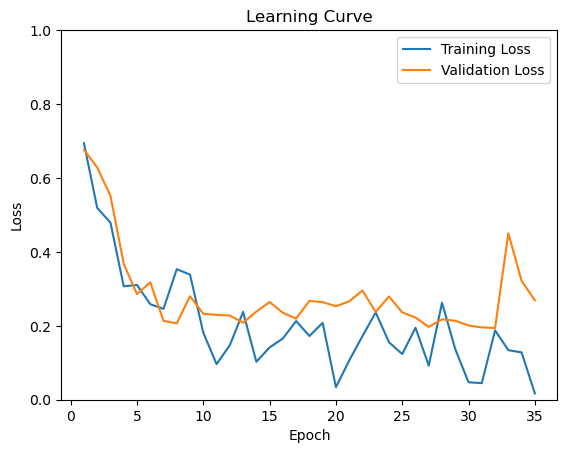

Fold 3
Accuracy Train: 0.9305555580627352. Accuracy valid: 0.8666666737624578
Recall Train: 0.773809552192688. Recall valid: 0.6619047522544861
Precision Train: 0.8170635104179382. Precision valid: 0.6523809432983398


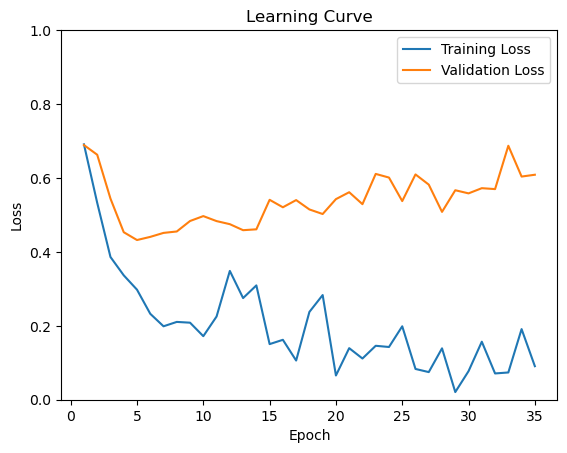

Fold 4
Accuracy Train: 0.9265873044019655. Accuracy valid: 0.7523809583414168
Recall Train: 0.785714328289032. Recall valid: 0.8952380418777466
Precision Train: 0.8380951881408691. Precision valid: 0.6968254498073033


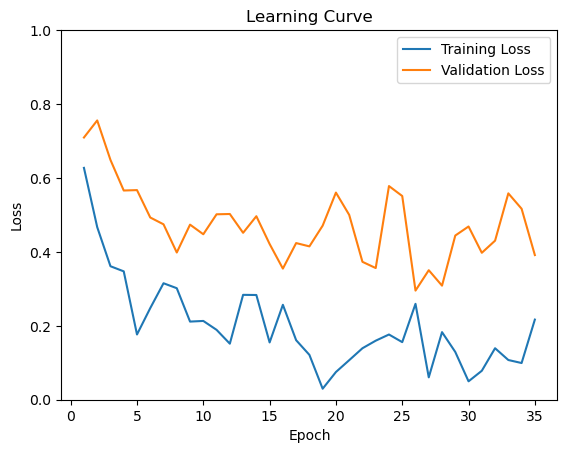

Fold 5
Accuracy Train: 0.9309523838616555. Accuracy valid: 0.8793650859878177
Recall Train: 0.7575397491455078. Recall valid: 0.6666666269302368
Precision Train: 0.8047619462013245. Precision valid: 0.6714285612106323


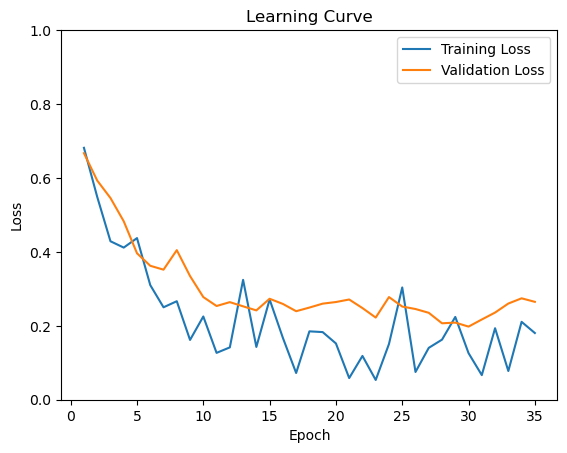

5
Fold 0: Training Loss: 0.2033381653683526, Validation Loss: 0.6690763836105664
Fold 1: Training Loss: 0.2069665125438145, Validation Loss: 0.2846869044005871
Fold 2: Training Loss: 0.20417352999959673, Validation Loss: 0.5387218122326192
Fold 3: Training Loss: 0.201038744194167, Validation Loss: 0.47580465057066507
Fold 4: Training Loss: 0.21801826613289968, Validation Loss: 0.30260145650023507
TRAIN LOSS MEDIA: 0.20670704364776613 VALID LOSS MEDIA: 0.45417824146293456
TRAIN ACC MEDIA: 0.928174605880465 VALID ACC MEDIA: 0.8279365157513393
TRAIN RECALL MEDIA: 0.7774603366851807 VALID RECALL MEDIA: 0.7009523510932922
TRAIN PRECISION MEDIA: 0.820555567741394 VALID PRECISION MEDIA: 0.6809523914541518


In [22]:
prueba_k_fold_resnet_no_pre(df_mean, 5, 35, optim.RMSprop , 3, 0.00001, False, None)

Fold 1
Accuracy Train: 0.9761904767581395. Accuracy valid: 0.49464285714285716
Recall Train: 0.9488571286201477. Recall valid: 0.4714285731315613
Precision Train: 0.9657142758369446. Precision valid: 0.5182653069496155


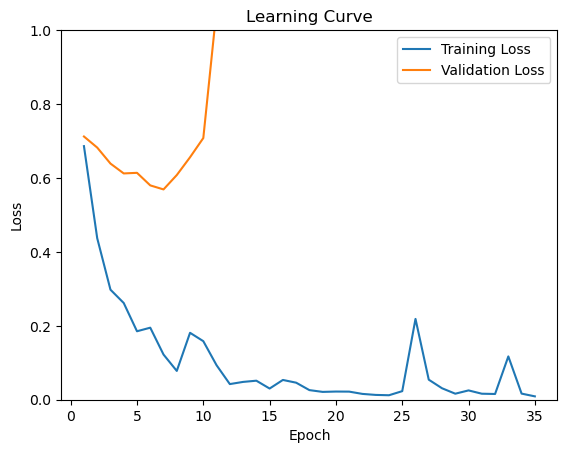

Fold 2
Accuracy Train: 0.9680952385493686. Accuracy valid: 0.8017857142857143
Recall Train: 0.9756598472595215. Recall valid: 0.7047619819641113
Precision Train: 0.9516667127609253. Precision valid: 0.7672619206564767


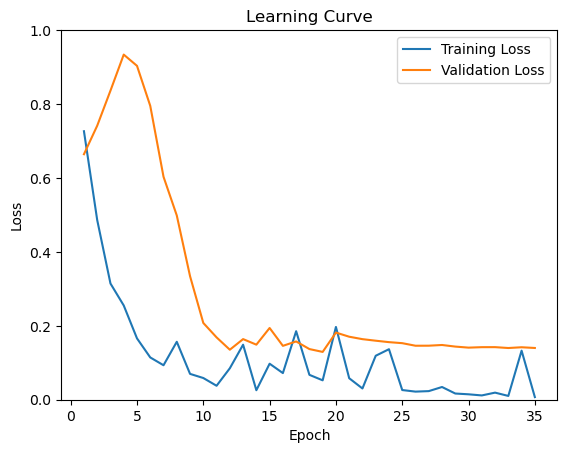

Fold 3
Accuracy Train: 0.9557142863954817. Accuracy valid: 0.8660714285714286
Recall Train: 0.9262856841087341. Recall valid: 0.7380952835083008
Precision Train: 0.9552381038665771. Precision valid: 0.8857142857142857


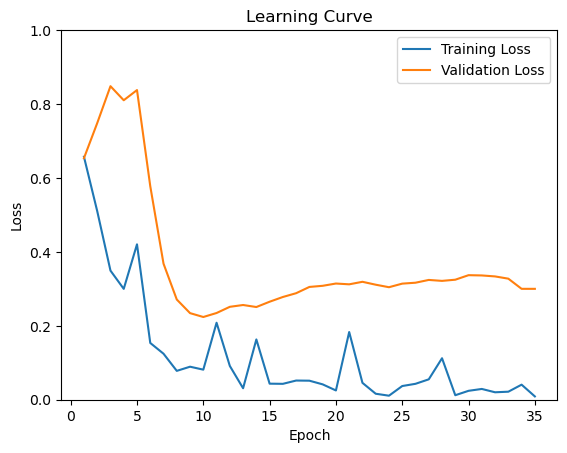

Fold 4
Accuracy Train: 0.9647619054998671. Accuracy valid: 0.8660714285714286
Recall Train: 0.9435238242149353. Recall valid: 0.40714284777641296
Precision Train: 0.9640475511550903. Precision valid: 0.34142857704843793


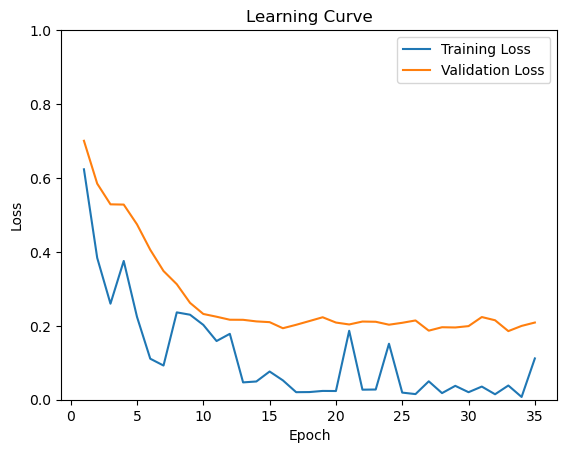

Fold 5
Accuracy Train: 0.9714285714285714. Accuracy valid: 0.75
Recall Train: 0.9437142610549927. Recall valid: 0.6499999761581421
Precision Train: 0.9528570771217346. Precision valid: 0.7300000020435878


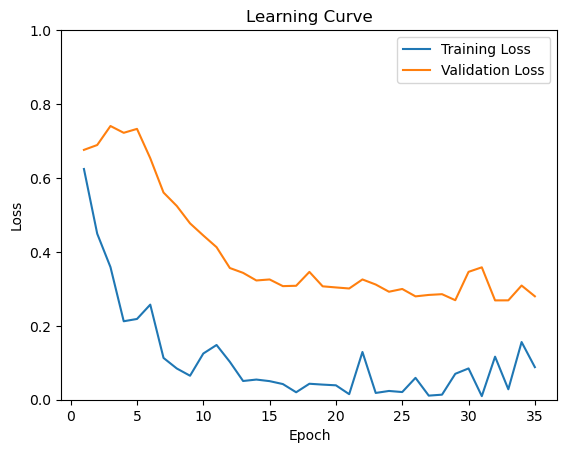

5
Fold 0: Training Loss: 0.10407569067818778, Validation Loss: 1.3710745402744837
Fold 1: Training Loss: 0.11635372928742851, Validation Loss: 0.29470341659284066
Fold 2: Training Loss: 0.11928210934357984, Validation Loss: 0.37451089772927976
Fold 3: Training Loss: 0.11858071883076003, Validation Loss: 0.27311180510691235
Fold 4: Training Loss: 0.11268220458711897, Validation Loss: 0.40089483431407386
TRAIN LOSS MEDIA: 0.11419489054541503 VALID LOSS MEDIA: 0.542859098803518
TRAIN ACC MEDIA: 0.9672380957262858 VALID ACC MEDIA: 0.7557142857142857
TRAIN RECALL MEDIA: 0.9476081728935242 VALID RECALL MEDIA: 0.594285786151886
TRAIN PRECISION MEDIA: 0.9579046964645386 VALID PRECISION MEDIA: 0.6485340184824808


In [23]:
prueba_k_fold_resnet_no_pre(df_mean, 5, 35, optim.RMSprop , 8, 0.00001, False, None)

Fold 1
Accuracy Train: 0.9613095249448503. Accuracy valid: 0.7333333483764104
Recall Train: 0.9005136489868164. Recall valid: 0.44999998807907104
Precision Train: 0.9214285612106323. Precision valid: 0.9155555563313621


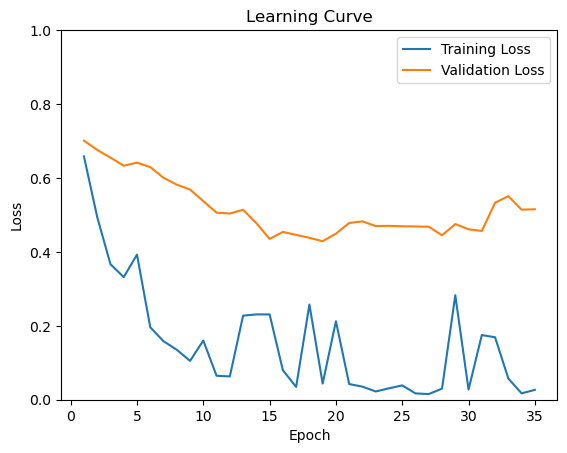

Fold 2
Accuracy Train: 0.9704365088826135. Accuracy valid: 0.7333333424159458
Recall Train: 0.9587302207946777. Recall valid: 0.9571428298950195
Precision Train: 0.943148136138916. Precision valid: 0.6513832313673836


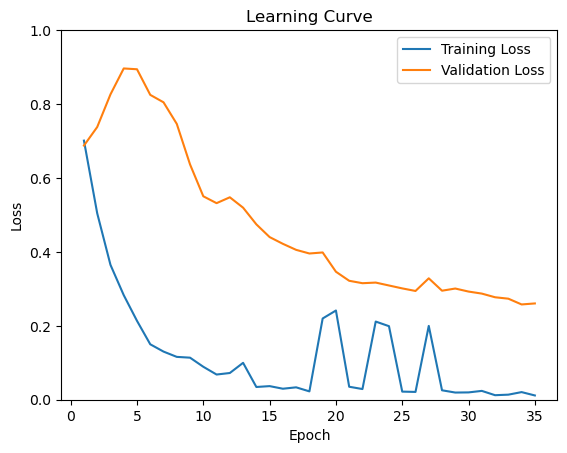

Fold 3
Accuracy Train: 0.9668650800273532. Accuracy valid: 0.8000000110694341
Recall Train: 0.925000011920929. Recall valid: 0.5857142806053162
Precision Train: 0.9523809535162789. Precision valid: 0.7841269842215947


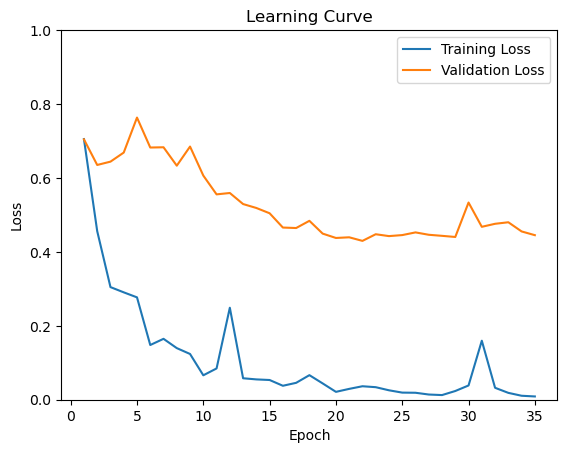

Fold 4
Accuracy Train: 0.9484127002102988. Accuracy valid: 0.7047619215079717
Recall Train: 0.8891344666481018. Recall valid: 0.7285714149475098
Precision Train: 0.9269840717315674. Precision valid: 0.5645351605755943


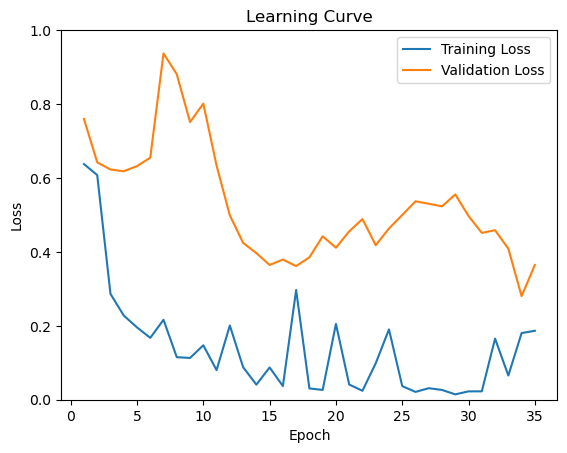

Fold 5
Accuracy Train: 0.9607142857142857. Accuracy valid: 0.7571428571428571
Recall Train: 0.9267762303352356. Recall valid: 0.5714285969734192
Precision Train: 0.9619048237800598. Precision valid: 0.7857142857142857


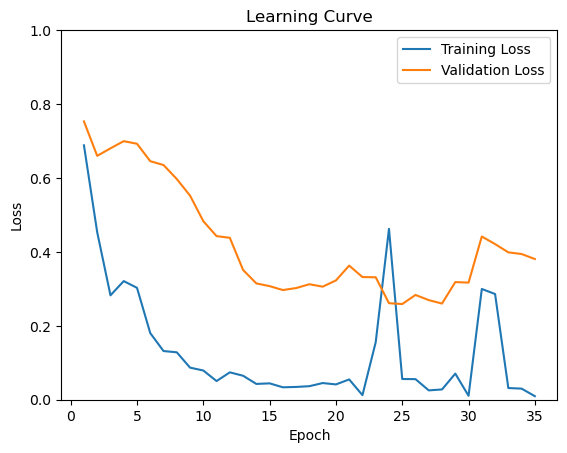

5
Fold 0: Training Loss: 0.15515811453972544, Validation Loss: 0.518141678401402
Fold 1: Training Loss: 0.12537538981331245, Validation Loss: 0.471931825365339
Fold 2: Training Loss: 0.11066071077116899, Validation Loss: 0.5291686117649078
Fold 3: Training Loss: 0.1409945785999298, Validation Loss: 0.5294155589171818
Fold 4: Training Loss: 0.13456527606717178, Validation Loss: 0.4235021948814392
TRAIN LOSS MEDIA: 0.1333508139582617 VALID LOSS MEDIA: 0.4944319738660539
TRAIN ACC MEDIA: 0.9615476199558802 VALID ACC MEDIA: 0.7457142961025238
TRAIN RECALL MEDIA: 0.9200308918952942 VALID RECALL MEDIA: 0.6585714221000671
TRAIN PRECISION MEDIA: 0.9411693092754909 VALID PRECISION MEDIA: 0.7402630436420441


In [24]:
prueba_k_fold_resnet_no_pre(df_mean, 5, 35, optim.RMSprop , 16, 0.00001, False, None)

## RMSProp DATA AUG

Fold 1
Accuracy Train: 0.9469387777605835. Accuracy valid: 0.7328571506908962
Recall Train: 0.913673460483551. Recall valid: 0.4357142746448517
Precision Train: 0.9435374736785889. Precision valid: 0.8357142857142857


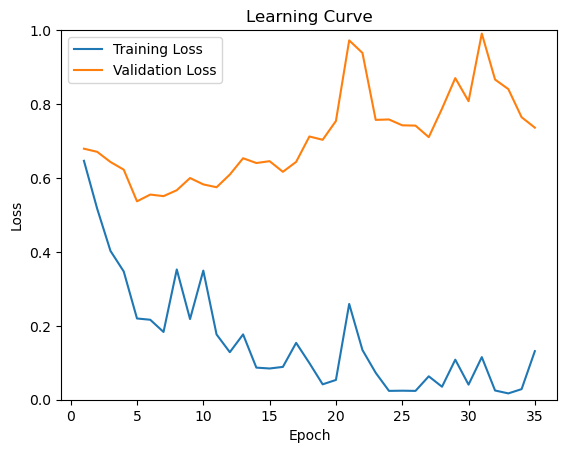

Fold 2
Accuracy Train: 0.9412244926301802. Accuracy valid: 0.8621428625924247
Recall Train: 0.8999319672584534. Recall valid: 0.8571429252624512
Precision Train: 0.9292517304420471. Precision valid: 0.9157142639160156


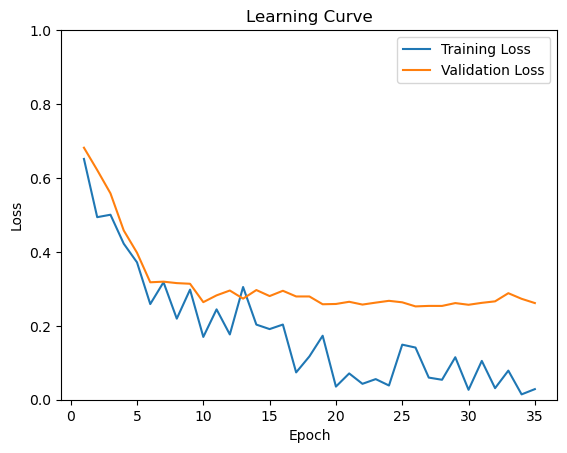

Fold 3
Accuracy Train: 0.9542857165239296. Accuracy valid: 0.8285714294229235
Recall Train: 0.9105442762374878. Recall valid: 0.7190477252006531
Precision Train: 0.9489796161651611. Precision valid: 0.8714285714285714


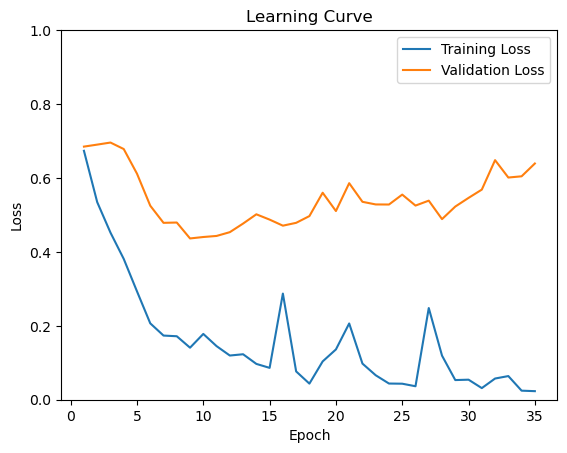

Fold 4
Accuracy Train: 0.941224492691001. Accuracy valid: 0.8292857187134879
Recall Train: 0.9082993268966675. Recall valid: 0.8333333134651184
Precision Train: 0.9390476942062378. Precision valid: 0.6842857156481061


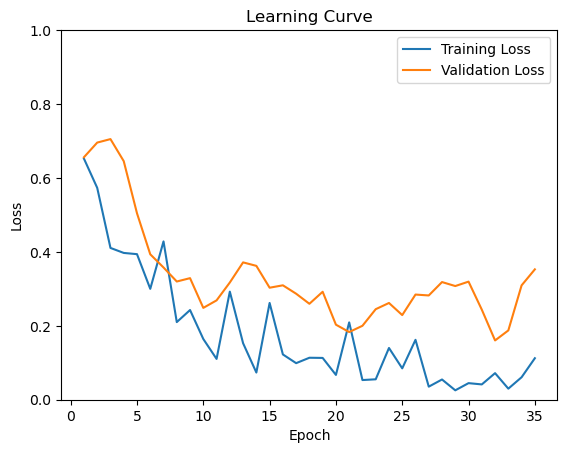

Fold 5
Accuracy Train: 0.9285714310726949. Accuracy valid: 0.8571428635290691
Recall Train: 0.846666693687439. Recall valid: 0.7714285850524902
Precision Train: 0.8617856502532959. Precision valid: 0.8476190498897007


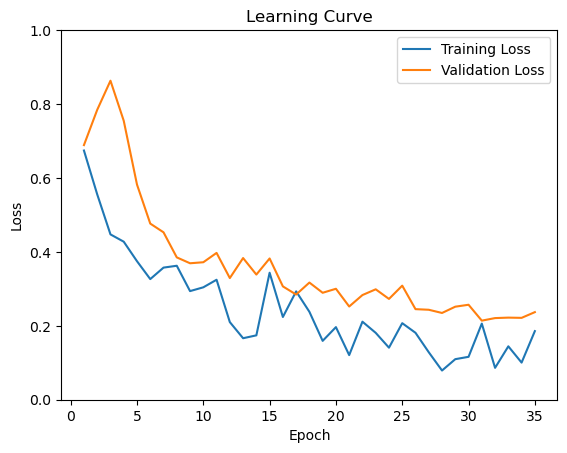

5
Fold 0: Training Loss: 0.16131624403808797, Validation Loss: 0.7098337522574834
Fold 1: Training Loss: 0.1839843887835741, Validation Loss: 0.31408233110393796
Fold 2: Training Loss: 0.1597646534975086, Validation Loss: 0.5432793658226729
Fold 3: Training Loss: 0.18172126375138759, Validation Loss: 0.3346816339663097
Fold 4: Training Loss: 0.24716944162334714, Validation Loss: 0.36628704848034044
TRAIN LOSS MEDIA: 0.1867911983387811 VALID LOSS MEDIA: 0.4536328263261488
TRAIN ACC MEDIA: 0.9424489821356777 VALID ACC MEDIA: 0.8220000049897603
TRAIN RECALL MEDIA: 0.8958231806755066 VALID RECALL MEDIA: 0.7233333587646484
TRAIN PRECISION MEDIA: 0.9245204925537109 VALID PRECISION MEDIA: 0.8309523773193359


In [25]:
prueba_k_fold_resnet_no_pre(df_mean, 5, 35, optim.RMSprop , 5, 0.00001, True, None)

Fold 1
Accuracy Train: 0.9591836752940196. Accuracy valid: 0.7300000075783049
Recall Train: 0.9591156840324402. Recall valid: 0.44999998807907104
Precision Train: 0.9404762387275696. Precision valid: 0.8342857139451163


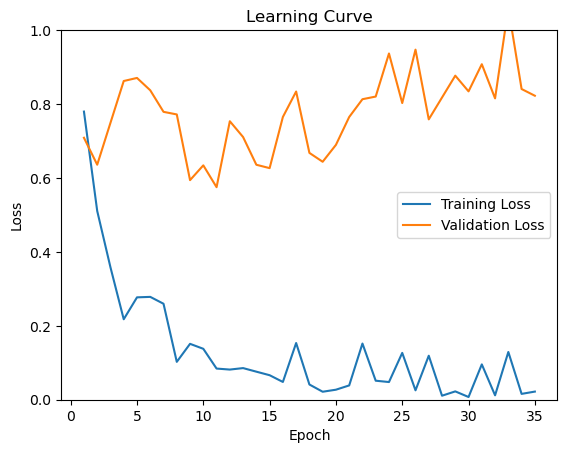

Fold 2
Accuracy Train: 0.9600000017759752. Accuracy valid: 0.8250000068119594
Recall Train: 0.9005442261695862. Recall valid: 0.8619048595428467
Precision Train: 0.9231292605400085. Precision valid: 0.8973809480667114


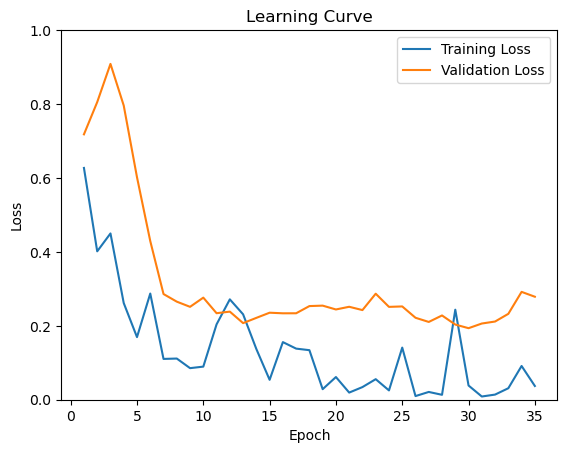

Fold 3
Accuracy Train: 0.951020410596108. Accuracy valid: 0.8314285721097674
Recall Train: 0.9324490427970886. Recall valid: 0.7333333492279053
Precision Train: 0.9328572154045105. Precision valid: 0.8857142857142857


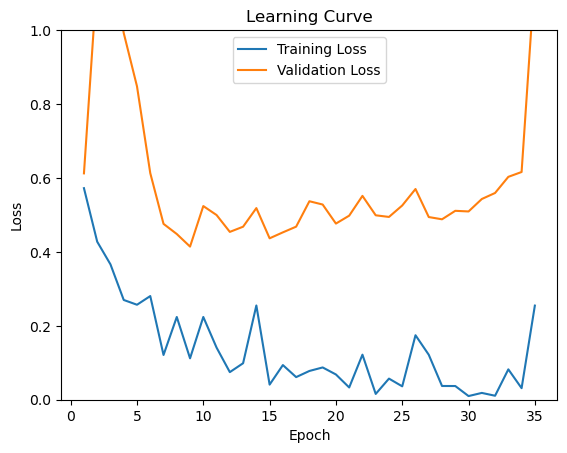

Fold 4
Accuracy Train: 0.9591836756589462. Accuracy valid: 0.835714287843023
Recall Train: 0.9300000071525574. Recall valid: 0.7285714149475098
Precision Train: 0.9393198490142822. Precision valid: 0.625


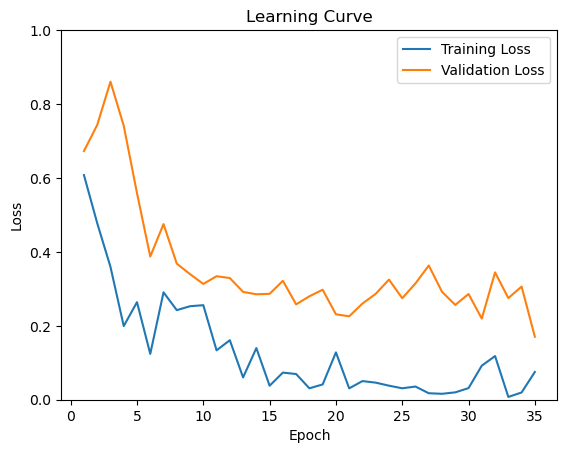

Fold 5
Accuracy Train: 0.9307142873959882. Accuracy valid: 0.8152381049735206
Recall Train: 0.8374999761581421. Recall valid: 0.8357142806053162
Precision Train: 0.8461309671401978. Precision valid: 0.9219047427177429


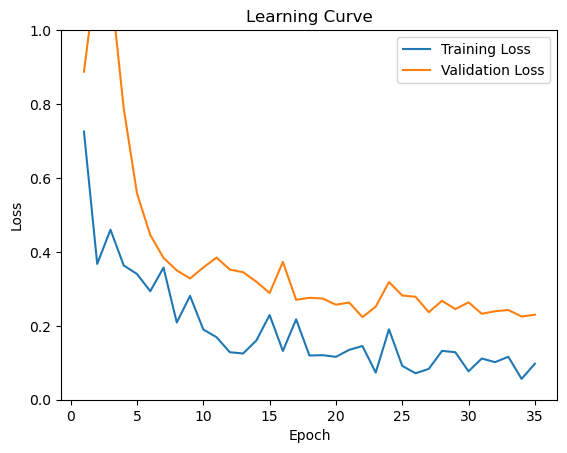

5
Fold 0: Training Loss: 0.1323966542657997, Validation Loss: 0.77609623670578
Fold 1: Training Loss: 0.13694041898208006, Validation Loss: 0.321614868220474
Fold 2: Training Loss: 0.13984532526561191, Validation Loss: 0.5921031367299813
Fold 3: Training Loss: 0.13083372955609646, Validation Loss: 0.359309004672936
Fold 4: Training Loss: 0.19189743463482176, Validation Loss: 0.381000085494348
TRAIN LOSS MEDIA: 0.14638271254088198 VALID LOSS MEDIA: 0.48602466636470376
TRAIN ACC MEDIA: 0.9520204101442074 VALID ACC MEDIA: 0.807476195863315
TRAIN RECALL MEDIA: 0.9119217991828918 VALID RECALL MEDIA: 0.7219048142433167
TRAIN PRECISION MEDIA: 0.9163826704025269 VALID PRECISION MEDIA: 0.8328571380887713


In [26]:
prueba_k_fold_resnet_no_pre(df_mean, 5, 35, optim.RMSprop , 5, 0.00001, True, 'G')

Fold 1
Accuracy Train: 0.9183673490066917. Accuracy valid: 0.6500000102179391
Recall Train: 0.9574829936027527. Recall valid: 0.5928571224212646
Precision Train: 0.9014965891838074. Precision valid: 0.7071428298950195


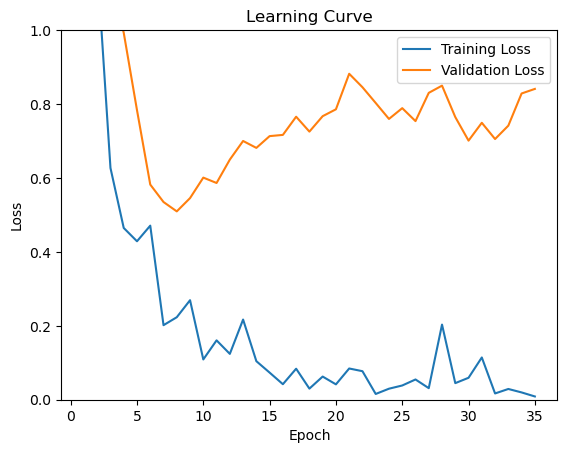

Fold 2
Accuracy Train: 0.9583673488120642. Accuracy valid: 0.8607142903975078
Recall Train: 0.9400680661201477. Recall valid: 0.8047619462013245
Precision Train: 0.9447618722915649. Precision valid: 0.8464285714285714


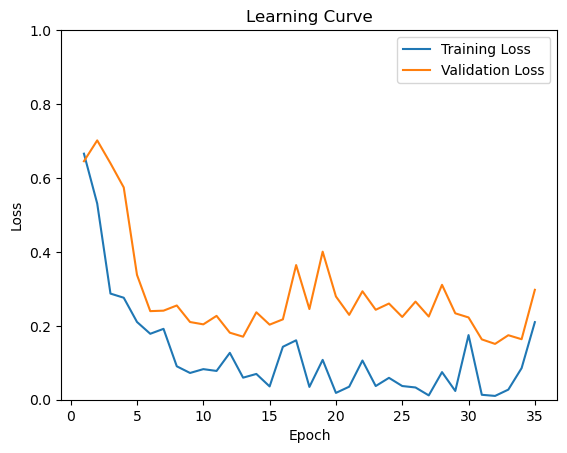

Fold 3
Accuracy Train: 0.951020410596108. Accuracy valid: 0.822142858164651
Recall Train: 0.8999319672584534. Recall valid: 0.7000000476837158
Precision Train: 0.9210885167121887. Precision valid: 0.8428571428571429


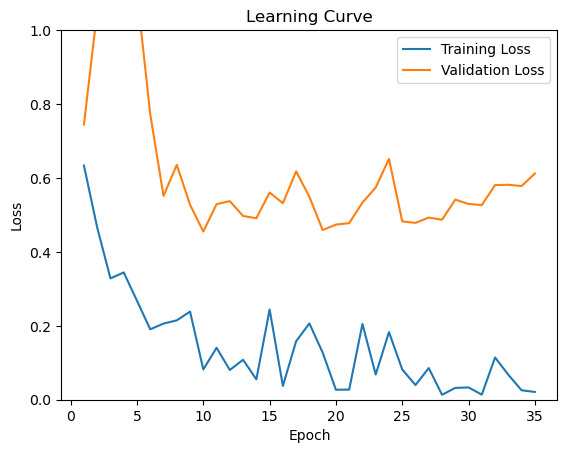

Fold 4
Accuracy Train: 0.9640816343073942. Accuracy valid: 0.8371428604636874
Recall Train: 0.959727942943573. Recall valid: 0.9666667580604553
Precision Train: 0.9526530504226685. Precision valid: 0.7300000020435878


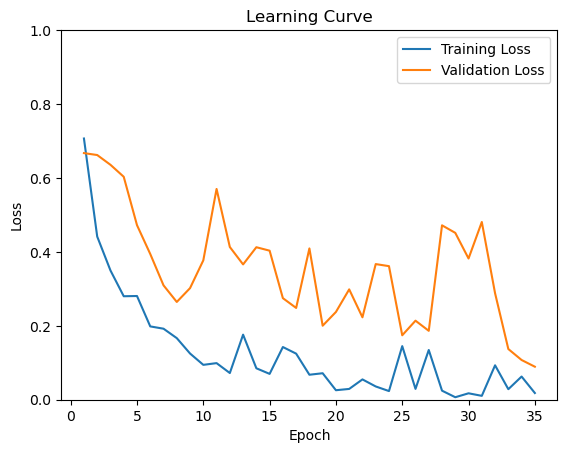

Fold 5
Accuracy Train: 0.9142857166273254. Accuracy valid: 0.7619047731161117
Recall Train: 0.7755952477455139. Recall valid: 0.5857142806053162
Precision Train: 0.8160714507102966. Precision valid: 0.7619047641754151


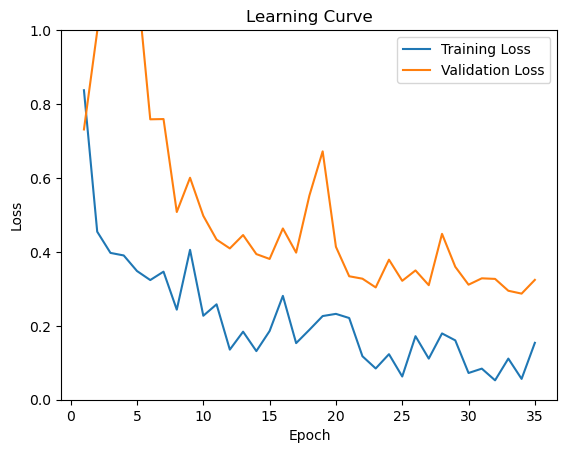

5
Fold 0: Training Loss: 0.2139342600745814, Validation Loss: 0.7770873410361153
Fold 1: Training Loss: 0.12456276996859482, Validation Loss: 0.2866388671632324
Fold 2: Training Loss: 0.14764079858681986, Validation Loss: 0.6230403050780297
Fold 3: Training Loss: 0.12809525672346353, Validation Loss: 0.3558918941766024
Fold 4: Training Loss: 0.22041345153536115, Validation Loss: 0.5212741430316653
TRAIN LOSS MEDIA: 0.16692930737776418 VALID LOSS MEDIA: 0.512786510097129
TRAIN ACC MEDIA: 0.9412244918699167 VALID ACC MEDIA: 0.7863809584719794
TRAIN RECALL MEDIA: 0.9065612554550171 VALID RECALL MEDIA: 0.7300000190734863
TRAIN PRECISION MEDIA: 0.9072142839431763 VALID PRECISION MEDIA: 0.7776666620799475


In [27]:
prueba_k_fold_resnet_no_pre(df_mean, 5, 35, optim.RMSprop , 5, 0.00001, True, 'H')

## ADAMW NO AUG

### PRUEBAS LR

Fold 1
Accuracy Train: 0.8865306173052107. Accuracy valid: 0.766428576196943
Recall Train: 0.8612245321273804. Recall valid: 0.5428571701049805
Precision Train: 0.8894557952880859. Precision valid: 0.8404761910438537


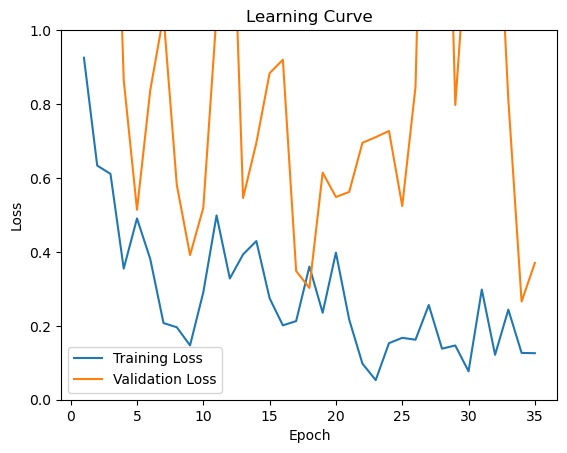

Fold 2
Accuracy Train: 0.8702040877877449. Accuracy valid: 0.6892857208848
Recall Train: 0.8479592204093933. Recall valid: 0.8380952477455139
Precision Train: 0.8656463027000427. Precision valid: 0.6102381071874073


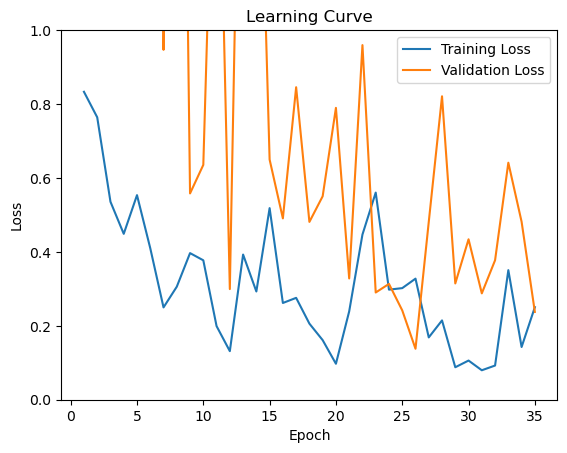

Fold 3
Accuracy Train: 0.8930612297690644. Accuracy valid: 0.7914285730038371
Recall Train: 0.8436053991317749. Recall valid: 0.8428571820259094
Precision Train: 0.88068026304245. Precision valid: 0.8835713863372803


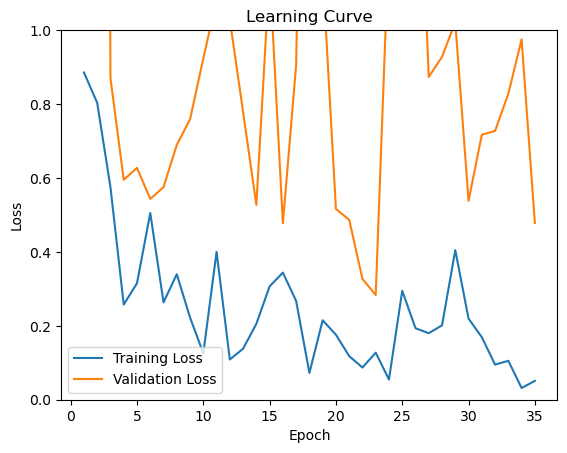

Fold 4
Accuracy Train: 0.8800000061794204. Accuracy valid: 0.824285717521395
Recall Train: 0.8391836881637573. Recall valid: 0.8761904835700989
Precision Train: 0.893129289150238. Precision valid: 0.7354761924062456


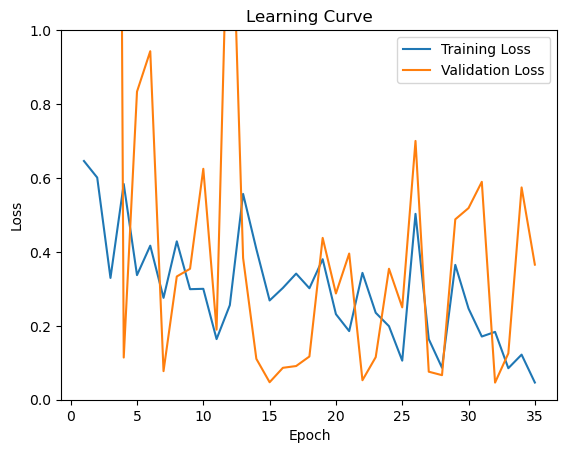

Fold 5
Accuracy Train: 0.8414285763565983. Accuracy valid: 0.7200000132833209
Recall Train: 0.7889285683631897. Recall valid: 0.8999999761581421
Precision Train: 0.8116071224212646. Precision valid: 0.6595238310950143


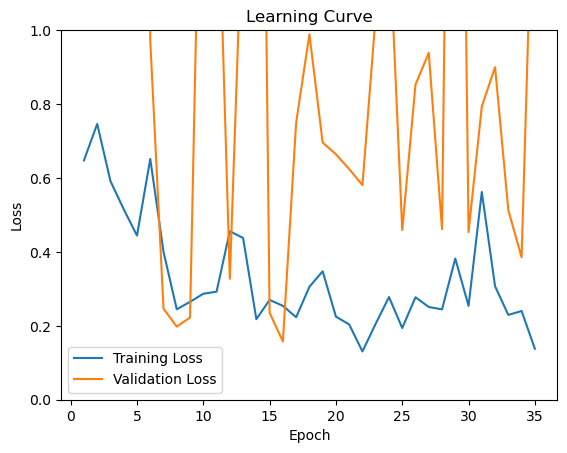

5
Fold 0: Training Loss: 0.28435163402131625, Validation Loss: 1.2188979315438442
Fold 1: Training Loss: 0.3165005353944642, Validation Loss: 2.9104645900128943
Fold 2: Training Loss: 0.25308719937290464, Validation Loss: 1.161596723110415
Fold 3: Training Loss: 0.29911584545459063, Validation Loss: 5.14577082604436
Fold 4: Training Loss: 0.33479868514197214, Validation Loss: 1.583897973490613
TRAIN LOSS MEDIA: 0.2975707798770496 VALID LOSS MEDIA: 2.404125608840425
TRAIN ACC MEDIA: 0.8742449034796078 VALID ACC MEDIA: 0.7582857201780592
TRAIN RECALL MEDIA: 0.8361803293228149 VALID RECALL MEDIA: 0.800000011920929
TRAIN PRECISION MEDIA: 0.8681038022041321 VALID PRECISION MEDIA: 0.7458571416139602


In [28]:
prueba_k_fold_resnet_no_pre(df_mean, 5, 35, optim.AdamW , 5, 0.001, False, None)

Fold 1
Accuracy Train: 0.9518367366523159. Accuracy valid: 0.7614285767078399
Recall Train: 0.9519728422164917. Recall valid: 0.6000000238418579
Precision Train: 0.9410884380340576. Precision valid: 0.9161904454231262


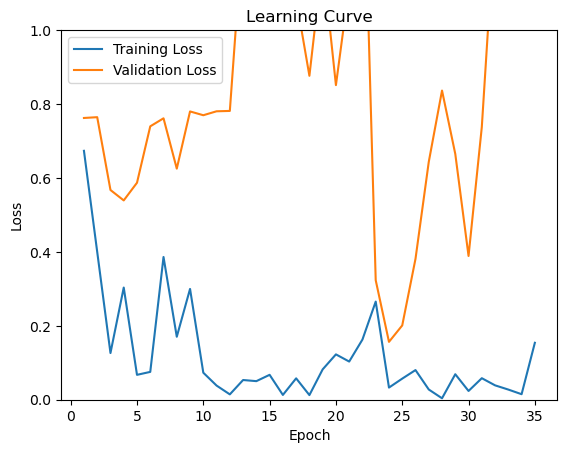

Fold 2
Accuracy Train: 0.9355102068915658. Accuracy valid: 0.8128571501799993
Recall Train: 0.8953061103820801. Recall valid: 0.8142857551574707
Precision Train: 0.9047619700431824. Precision valid: 0.805238105569567


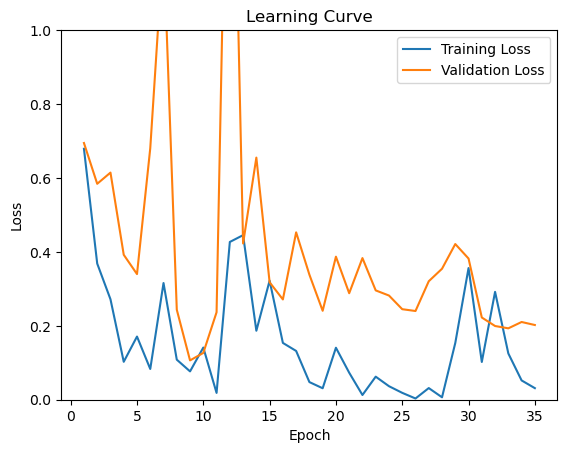

Fold 3
Accuracy Train: 0.9485714309677785. Accuracy valid: 0.817142858675548
Recall Train: 0.9131293296813965. Recall valid: 0.7619048357009888
Precision Train: 0.9251700043678284. Precision valid: 0.8571428605488368


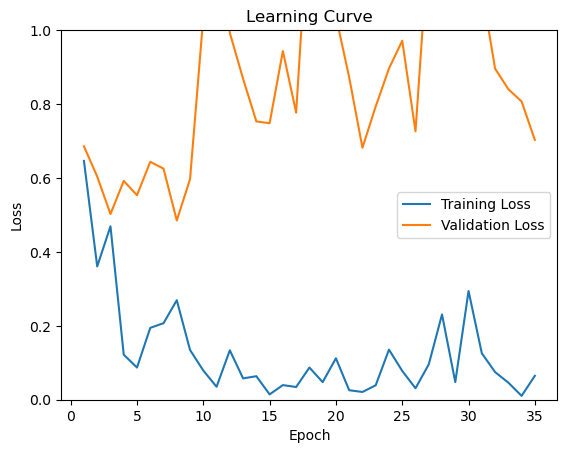

Fold 4
Accuracy Train: 0.9444897988012859. Accuracy valid: 0.7771428610597338
Recall Train: 0.9163945913314819. Recall valid: 0.8142856955528259
Precision Train: 0.9346939325332642. Precision valid: 0.6035714319774083


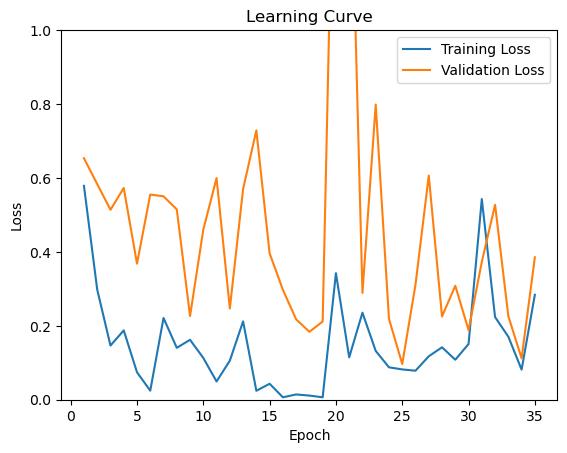

Fold 5
Accuracy Train: 0.9064285734934466. Accuracy valid: 0.7200000141348157
Recall Train: 0.8394047617912292. Recall valid: 0.8571428656578064
Precision Train: 0.8272619247436523. Precision valid: 0.7614285945892334


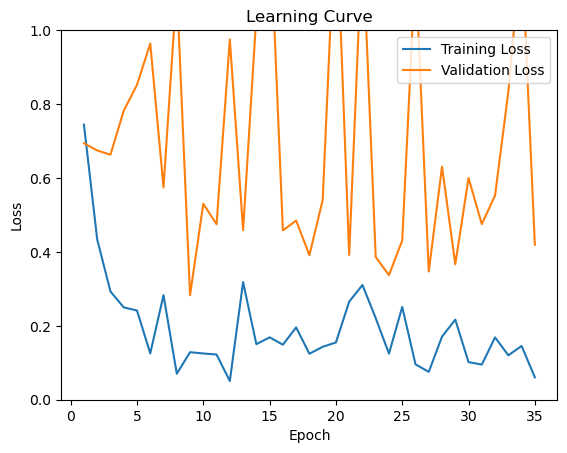

5
Fold 0: Training Loss: 0.12018980023318103, Validation Loss: 0.8905500565256391
Fold 1: Training Loss: 0.1594160253913807, Validation Loss: 0.417917588659163
Fold 2: Training Loss: 0.12900120626602854, Validation Loss: 0.9795762984057157
Fold 3: Training Loss: 0.1517890283039638, Validation Loss: 0.47473485661404474
Fold 4: Training Loss: 0.1912539659866265, Validation Loss: 0.6869720290281943
TRAIN LOSS MEDIA: 0.1503300052362361 VALID LOSS MEDIA: 0.6899501658465514
TRAIN ACC MEDIA: 0.9373673493612786 VALID ACC MEDIA: 0.7777142921515874
TRAIN RECALL MEDIA: 0.9032415151596069 VALID RECALL MEDIA: 0.7695238590240479
TRAIN PRECISION MEDIA: 0.9065952301025391 VALID PRECISION MEDIA: 0.7887142876216343


In [29]:
prueba_k_fold_resnet_no_pre(df_mean, 5, 35, optim.AdamW , 5, 0.0001, False, None)

Fold 1
Accuracy Train: 0.959183675537304. Accuracy valid: 0.7257142935480391
Recall Train: 0.923265278339386. Recall valid: 0.4214285612106323
Precision Train: 0.9585034251213074. Precision valid: 0.8071428571428572


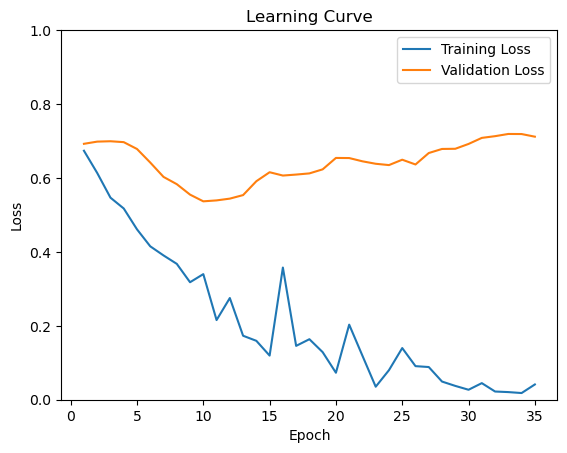

Fold 2
Accuracy Train: 0.9240816357184428. Accuracy valid: 0.6971428662538528
Recall Train: 0.9480272531509399. Recall valid: 0.8476190567016602
Precision Train: 0.902721107006073. Precision valid: 0.6569047570228577


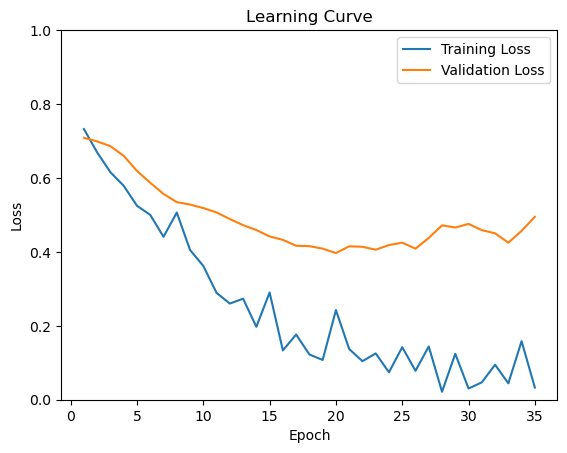

Fold 3
Accuracy Train: 0.9371428591256239. Accuracy valid: 0.809285715009485
Recall Train: 0.9655102491378784. Recall valid: 0.8571429252624512
Precision Train: 0.9134694337844849. Precision valid: 0.9083333015441895


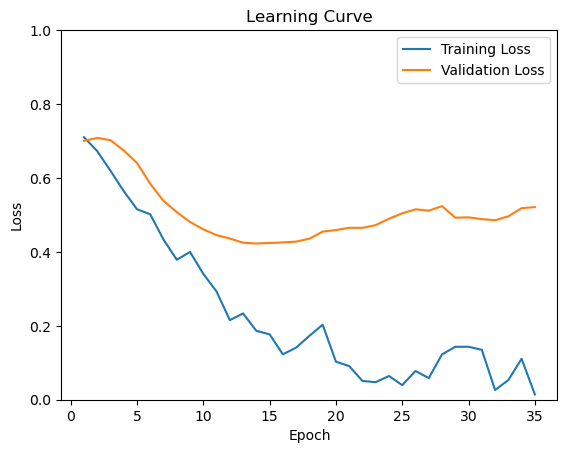

Fold 4
Accuracy Train: 0.925714288864817. Accuracy valid: 0.8135714347873415
Recall Train: 0.826938807964325. Recall valid: 0.8238095641136169
Precision Train: 0.8877551048994065. Precision valid: 0.6750000017029899


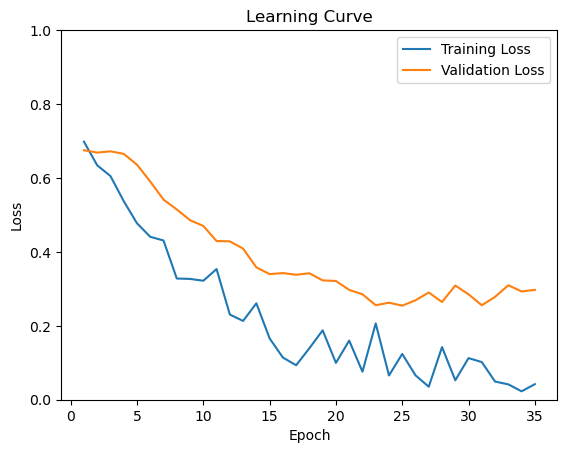

Fold 5
Accuracy Train: 0.8835714315729482. Accuracy valid: 0.6276190583195005
Recall Train: 0.7074404954910278. Recall valid: 0.5357142686843872
Precision Train: 0.7589285714285714. Precision valid: 0.5476190532956805


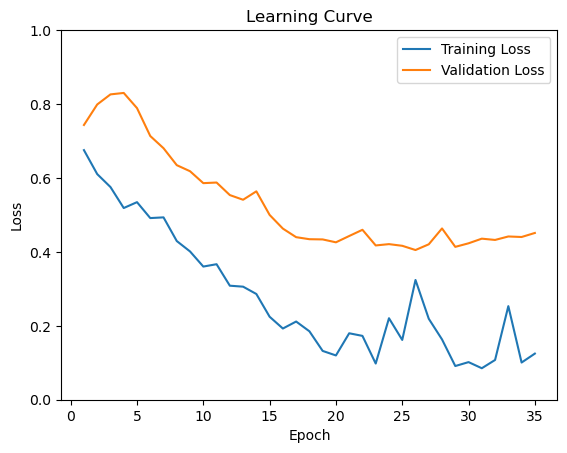

5
Fold 0: Training Loss: 0.2134586730173656, Validation Loss: 0.6422905436583928
Fold 1: Training Loss: 0.25101772035871234, Validation Loss: 0.49026743812220436
Fold 2: Training Loss: 0.23319186456501484, Validation Loss: 0.5084631770849228
Fold 3: Training Loss: 0.22732804007828236, Validation Loss: 0.3930644371679851
Fold 4: Training Loss: 0.28073862705911906, Validation Loss: 0.5327891560537474
TRAIN LOSS MEDIA: 0.2411469850156988 VALID LOSS MEDIA: 0.5133749504174505
TRAIN ACC MEDIA: 0.9259387781638273 VALID ACC MEDIA: 0.7346666735836438
TRAIN RECALL MEDIA: 0.8742364645004272 VALID RECALL MEDIA: 0.6971428990364075
TRAIN PRECISION MEDIA: 0.8842755284479686 VALID PRECISION MEDIA: 0.7189999941417149


In [30]:
prueba_k_fold_resnet_no_pre(df_mean, 5, 35, optim.AdamW , 5, 0.00001, False, None)

### PRUEBAS BS

Fold 1
Accuracy Train: 0.8857142895460128. Accuracy valid: 0.765079377662568
Recall Train: 0.7837302088737488. Recall valid: 0.561904788017273
Precision Train: 0.7825396656990051. Precision valid: 0.6476190090179443


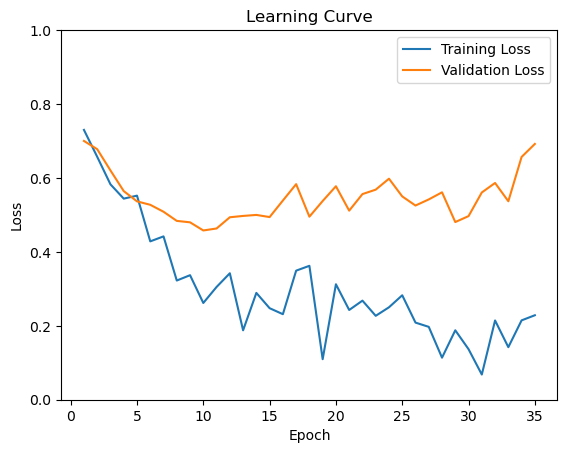

Fold 2
Accuracy Train: 0.8785714316226187. Accuracy valid: 0.7301587382952373
Recall Train: 0.8261904716491699. Recall valid: 0.7333333492279053
Precision Train: 0.7964285612106323. Precision valid: 0.6142856478691101


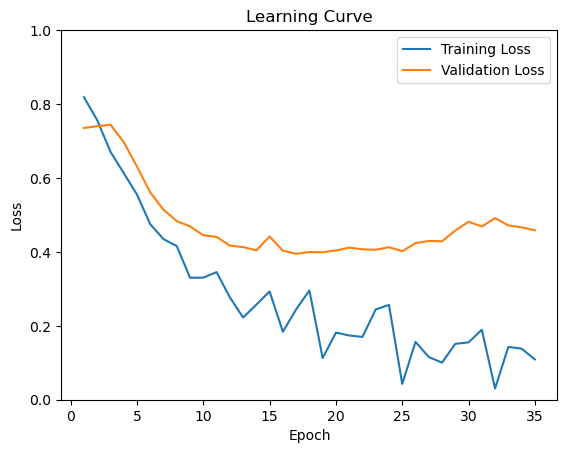

Fold 3
Accuracy Train: 0.9190476220278512. Accuracy valid: 0.8730158797332219
Recall Train: 0.798015832901001. Recall valid: 0.6761904358863831
Precision Train: 0.8345238566398621. Precision valid: 0.6603174209594727


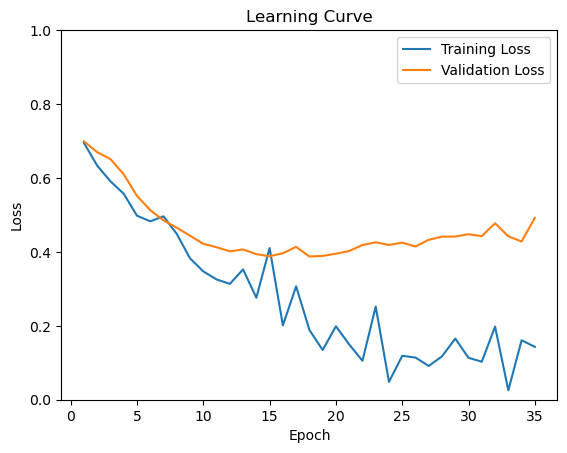

Fold 4
Accuracy Train: 0.8984127018423308. Accuracy valid: 0.7174603297596887
Recall Train: 0.8043650984764099. Recall valid: 0.8904761672019958
Precision Train: 0.8285714387893677. Precision valid: 0.6285714609282357


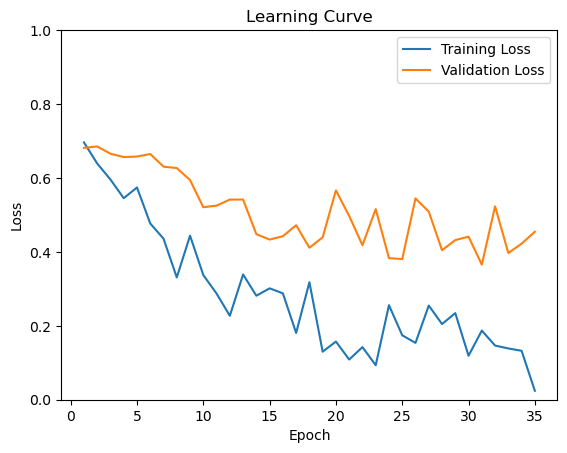

Fold 5
Accuracy Train: 0.9047619090903373. Accuracy valid: 0.9079365097341084
Recall Train: 0.7432540059089661. Recall valid: 0.8666666150093079
Precision Train: 0.8035714030265808. Precision valid: 0.8333333321980068


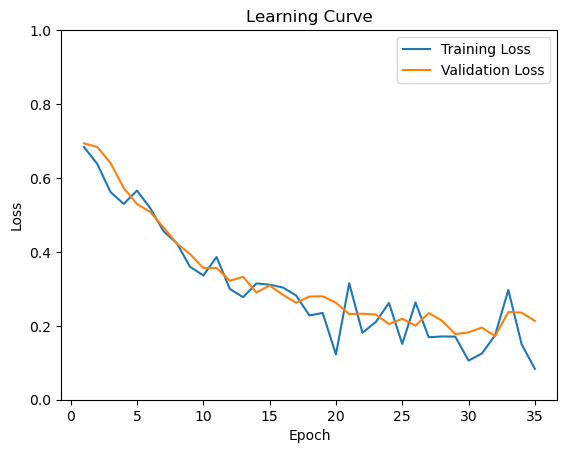

5
Fold 0: Training Loss: 0.30220655437026706, Validation Loss: 0.5474747298728851
Fold 1: Training Loss: 0.2853981448603528, Validation Loss: 0.4786092749663763
Fold 2: Training Loss: 0.27841322044176714, Validation Loss: 0.4584363939506667
Fold 3: Training Loss: 0.2844212693827493, Validation Loss: 0.5112408551431837
Fold 4: Training Loss: 0.3046550931675093, Validation Loss: 0.3264796030663309
TRAIN LOSS MEDIA: 0.29101885644452913 VALID LOSS MEDIA: 0.4644481713998886
TRAIN ACC MEDIA: 0.8973015908258303 VALID ACC MEDIA: 0.7987301670369649
TRAIN RECALL MEDIA: 0.7911111116409302 VALID RECALL MEDIA: 0.7457143068313599
TRAIN PRECISION MEDIA: 0.8091269731521606 VALID PRECISION MEDIA: 0.6768253741945539


In [31]:
prueba_k_fold_resnet_no_pre(df_mean, 5, 35, optim.AdamW , 3, 0.00001, False, None)

Fold 1
Accuracy Train: 0.9490476197855815. Accuracy valid: 0.41785714285714287
Recall Train: 0.949755072593689. Recall valid: 0.2809523642063141
Precision Train: 0.9503945708274841. Precision valid: 0.45714285714285713


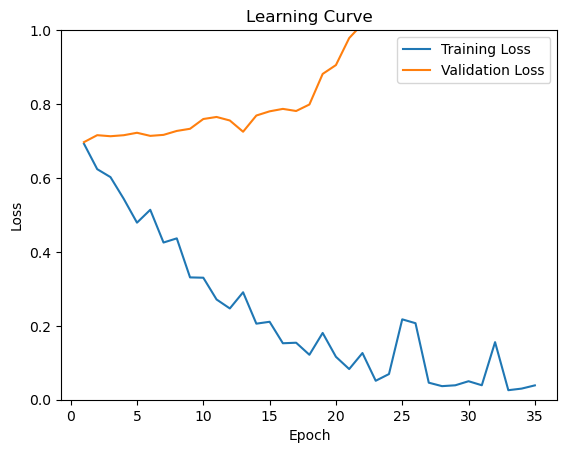

Fold 2
Accuracy Train: 0.932142857994352. Accuracy valid: 0.8053571428571429
Recall Train: 0.8335102200508118. Recall valid: 0.5999999642372131
Precision Train: 0.8742857170956475. Precision valid: 0.8571428571428571


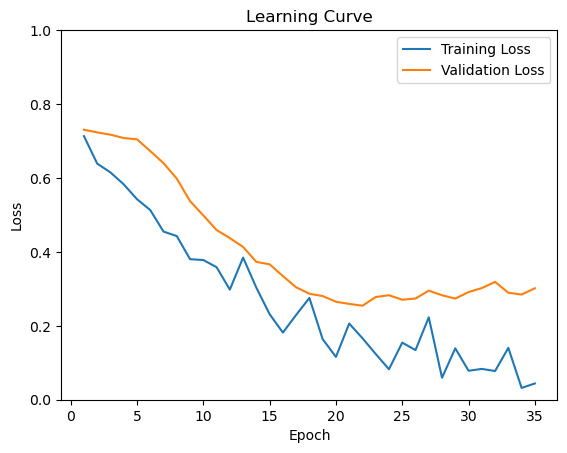

Fold 3
Accuracy Train: 0.904761905840465. Accuracy valid: 0.8946428571428572
Recall Train: 0.9666122198104858. Recall valid: 0.8619048595428467
Precision Train: 0.8770203590393066. Precision valid: 0.9353572130203247


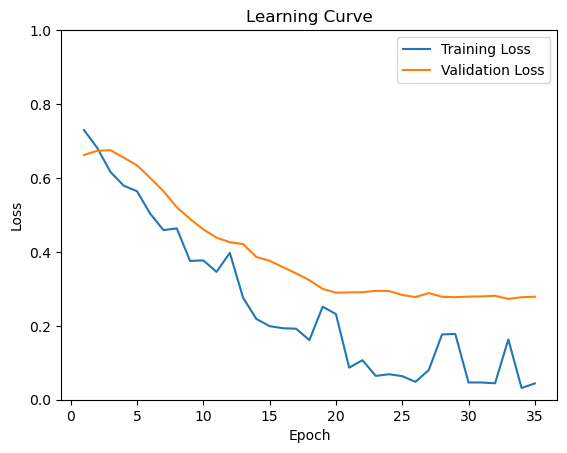

Fold 4
Accuracy Train: 0.9397619054998672. Accuracy valid: 0.7517857142857143
Recall Train: 0.9393197298049927. Recall valid: 0.5
Precision Train: 0.892217755317688. Precision valid: 0.31768709421157837


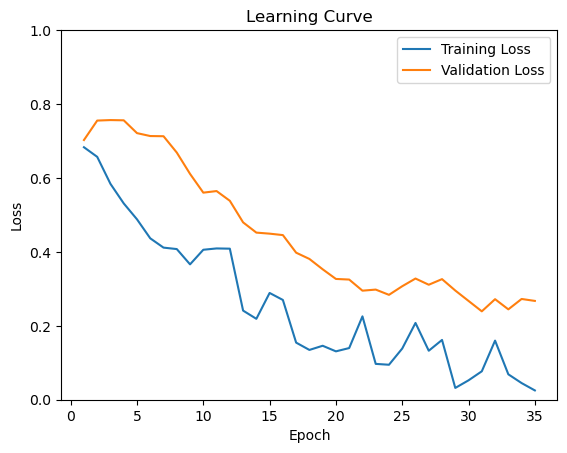

Fold 5
Accuracy Train: 0.9235714285714286. Accuracy valid: 0.8
Recall Train: 0.8560272455215454. Recall valid: 0.6000000238418579
Precision Train: 0.9161904782056809. Precision valid: 0.7714285714285715


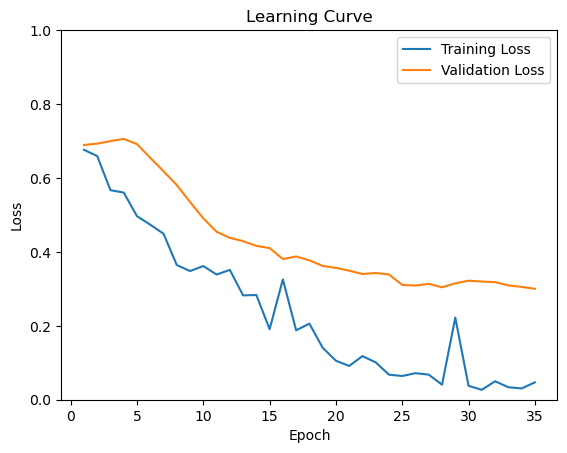

5
Fold 0: Training Loss: 0.2327195219695568, Validation Loss: 0.9469635073627745
Fold 1: Training Loss: 0.27278769069484304, Validation Loss: 0.4088136651154075
Fold 2: Training Loss: 0.25903865290539607, Validation Loss: 0.39541072590010506
Fold 3: Training Loss: 0.25805408720459255, Validation Loss: 0.44796206046428
Fold 4: Training Loss: 0.24110069567603723, Validation Loss: 0.43337558933666775
TRAIN LOSS MEDIA: 0.25274012969008514 VALID LOSS MEDIA: 0.5265051096358471
TRAIN ACC MEDIA: 0.9298571435383389 VALID ACC MEDIA: 0.7339285714285714
TRAIN RECALL MEDIA: 0.9090448617935181 VALID RECALL MEDIA: 0.5685714483261108
TRAIN PRECISION MEDIA: 0.9020217760971614 VALID PRECISION MEDIA: 0.6677517185892377


In [32]:
prueba_k_fold_resnet_no_pre(df_mean, 5, 35, optim.AdamW , 8, 0.00001, False, None)

Fold 1
Accuracy Train: 0.9226190493220374. Accuracy valid: 0.6952381134033203
Recall Train: 0.8309637308120728. Recall valid: 0.3142857253551483
Precision Train: 0.8952380997794015. Precision valid: 0.6571428571428571


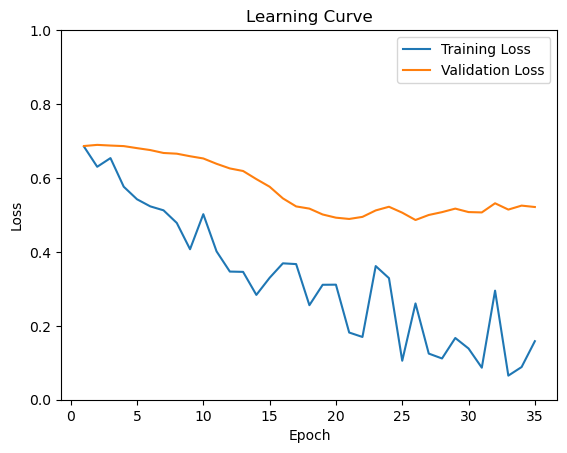

Fold 2
Accuracy Train: 0.8724206362451826. Accuracy valid: 0.6730158848421914
Recall Train: 0.9536796808242798. Recall valid: 1.0
Precision Train: 0.8721429109573364. Precision valid: 0.593197226524353


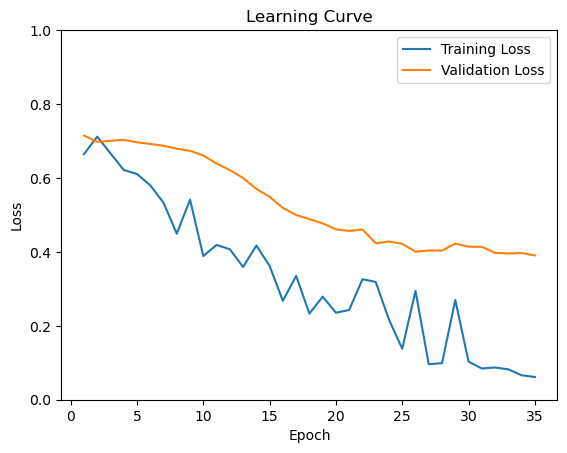

Fold 3
Accuracy Train: 0.8236111130033219. Accuracy valid: 0.7111111189637865
Recall Train: 0.9515873789787292. Recall valid: 0.8428571224212646
Precision Train: 0.7982915043830872. Precision valid: 0.7539682388305664


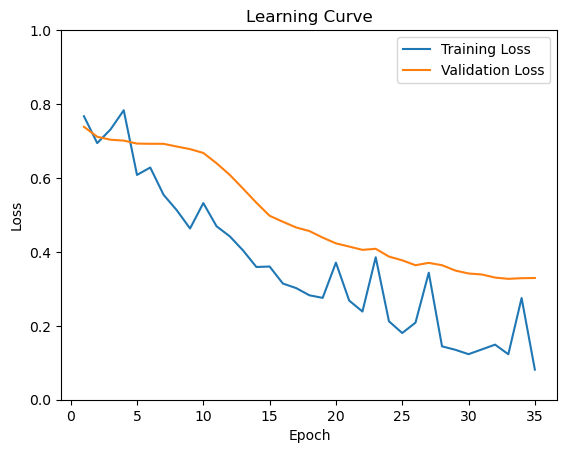

Fold 4
Accuracy Train: 0.8900793671607973. Accuracy valid: 0.6603174805641174
Recall Train: 0.7552081942558289. Recall valid: 0.5428571701049805
Precision Train: 0.8476190515926906. Precision valid: 0.4376190594264439


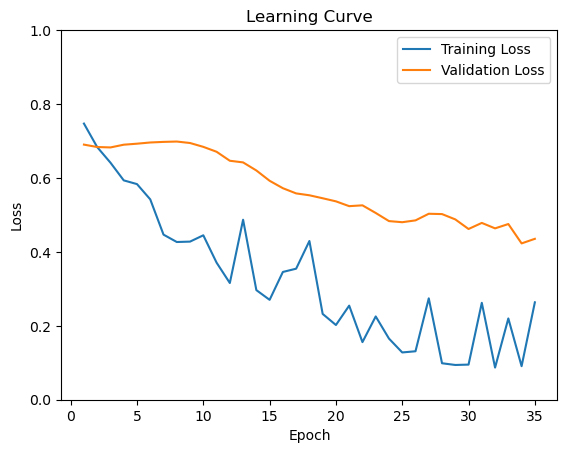

Fold 5
Accuracy Train: 0.9065476190476189. Accuracy valid: 0.7
Recall Train: 0.7995049357414246. Recall valid: 0.4000000059604645
Precision Train: 0.8857142891202654. Precision valid: 0.6285714285714286


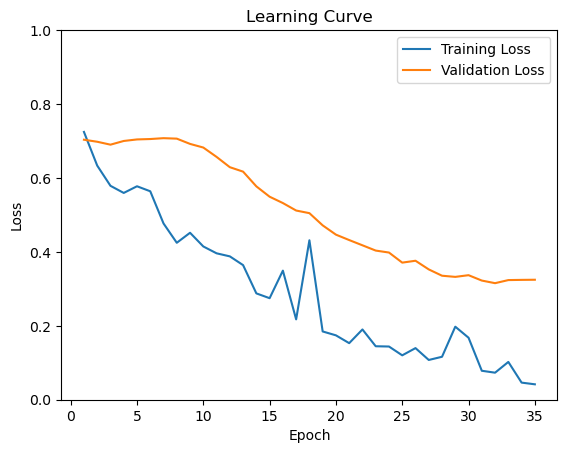

5
Fold 0: Training Loss: 0.3278865805694035, Validation Loss: 0.5722131746155875
Fold 1: Training Loss: 0.3305129794137818, Validation Loss: 0.5302638045379093
Fold 2: Training Loss: 0.3674034425190517, Validation Loss: 0.5004286101886204
Fold 3: Training Loss: 0.32534060520785196, Validation Loss: 0.5737837510449546
Fold 4: Training Loss: 0.29415775441697667, Validation Loss: 0.5100772133895329
TRAIN LOSS MEDIA: 0.32906027242541314 VALID LOSS MEDIA: 0.537353310755321
TRAIN ACC MEDIA: 0.8830555569557916 VALID ACC MEDIA: 0.6879365195546832
TRAIN RECALL MEDIA: 0.858188807964325 VALID RECALL MEDIA: 0.6200000047683716
TRAIN PRECISION MEDIA: 0.8598011711665562 VALID PRECISION MEDIA: 0.6140997620991298


In [33]:
prueba_k_fold_resnet_no_pre(df_mean, 5, 35, optim.AdamW , 16, 0.00001, False, None)

## ADAMW DATA AUG

Fold 1
Accuracy Train: 0.919183677252458. Accuracy valid: 0.7421428633587701
Recall Train: 0.9391157031059265. Recall valid: 0.5357142686843872
Precision Train: 0.9048299789428711. Precision valid: 0.905238151550293


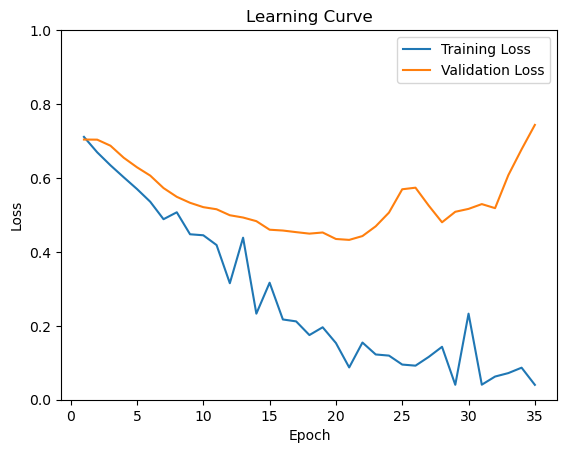

Fold 2
Accuracy Train: 0.8857142908232553. Accuracy valid: 0.8278571507760457
Recall Train: 0.7670068740844727. Recall valid: 0.6714285016059875
Precision Train: 0.8448979590620314. Precision valid: 0.8857142857142857


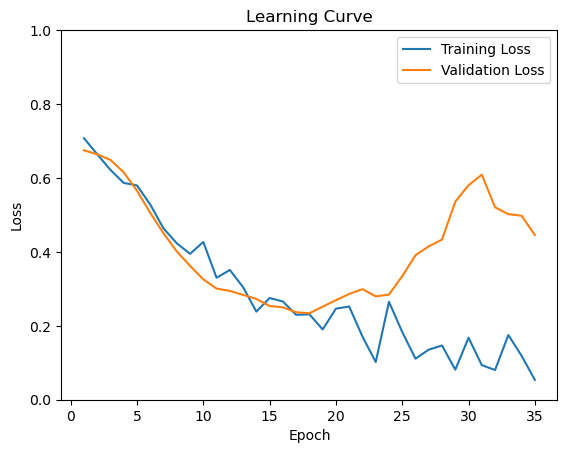

Fold 3
Accuracy Train: 0.8530612294771233. Accuracy valid: 0.7964285724929401
Recall Train: 0.9528570771217346. Recall valid: 0.8571429252624512
Precision Train: 0.8323129415512085. Precision valid: 0.8797618746757507


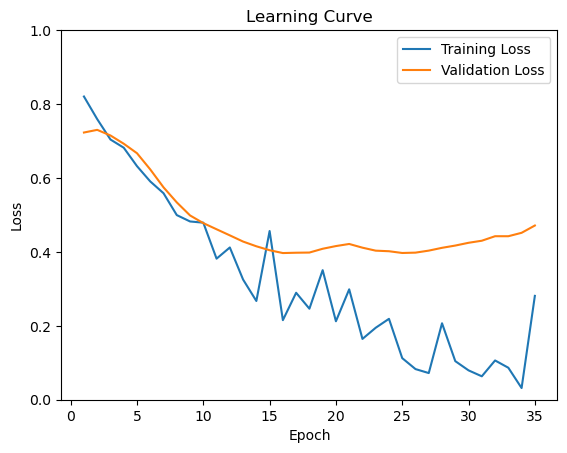

Fold 4
Accuracy Train: 0.8669387810692495. Accuracy valid: 0.690714292866843
Recall Train: 0.9047619104385376. Recall valid: 1.0
Precision Train: 0.8735374212265015. Precision valid: 0.5745238065719604


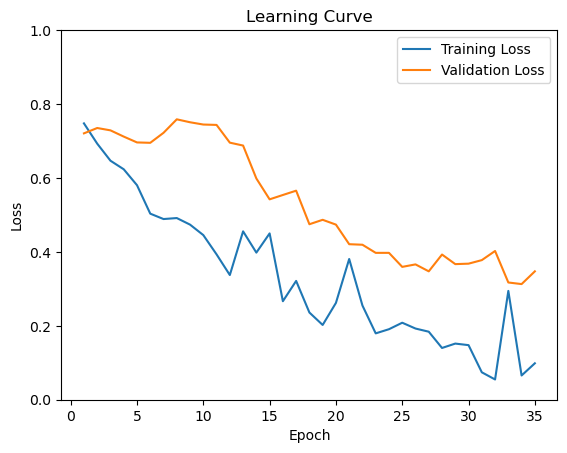

Fold 5
Accuracy Train: 0.875000004310693. Accuracy valid: 0.7676190589155469
Recall Train: 0.7403571009635925. Recall valid: 0.6571428775787354
Precision Train: 0.8077380657196045. Precision valid: 0.826190481867109


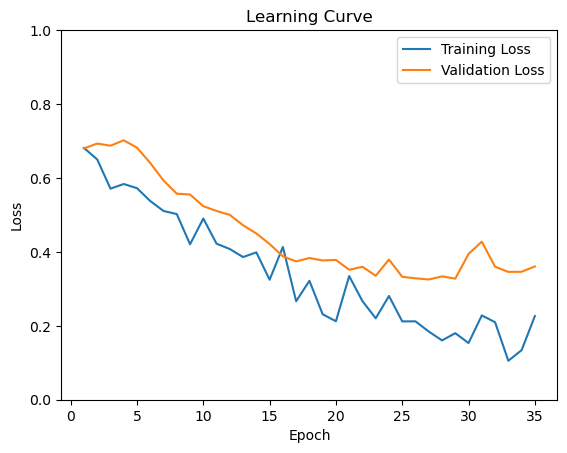

5
Fold 0: Training Loss: 0.2797508244003568, Validation Loss: 0.5416790051119668
Fold 1: Training Loss: 0.2912966892123222, Validation Loss: 0.4078446806541511
Fold 2: Training Loss: 0.32763532187257494, Validation Loss: 0.47807790796671595
Fold 3: Training Loss: 0.33240864010793825, Validation Loss: 0.5336956935269492
Fold 4: Training Loss: 0.3432082942553929, Validation Loss: 0.45361228329794745
TRAIN LOSS MEDIA: 0.314859953969717 VALID LOSS MEDIA: 0.4829819141115461
TRAIN ACC MEDIA: 0.8799795965865558 VALID ACC MEDIA: 0.7649523876820292
TRAIN RECALL MEDIA: 0.8608196973800659 VALID RECALL MEDIA: 0.7442857027053833
TRAIN PRECISION MEDIA: 0.8526632733004433 VALID PRECISION MEDIA: 0.8142857200758797


In [34]:
prueba_k_fold_resnet_no_pre(df_mean, 5, 35, optim.AdamW , 5, 0.00001, True, None)

Fold 1
Accuracy Train: 0.921632656394219. Accuracy valid: 0.6678571539265769
Recall Train: 0.8452380895614624. Recall valid: 0.4000000059604645
Precision Train: 0.9000000008514949. Precision valid: 0.6428571428571429


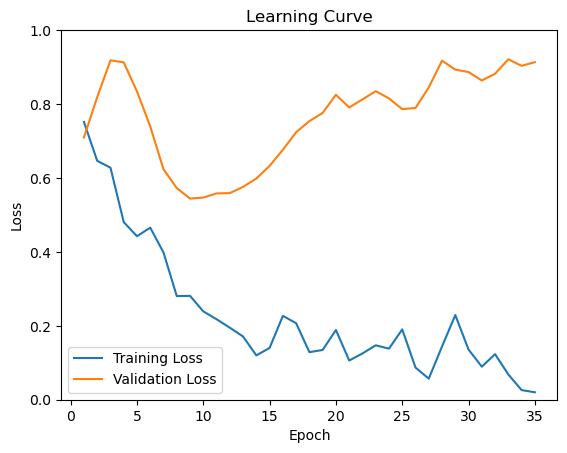

Fold 2
Accuracy Train: 0.9453061249183149. Accuracy valid: 0.8764285785811288
Recall Train: 0.8811565041542053. Recall valid: 0.7999999523162842
Precision Train: 0.9190476213182722. Precision valid: 0.9928571581840515


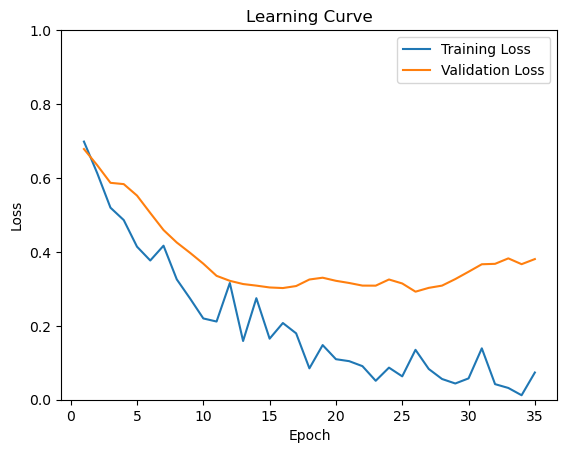

Fold 3
Accuracy Train: 0.9297959217003413. Accuracy valid: 0.8150000010217939
Recall Train: 0.8678911328315735. Recall valid: 0.6904762983322144
Precision Train: 0.918367326259613. Precision valid: 0.8285714285714286


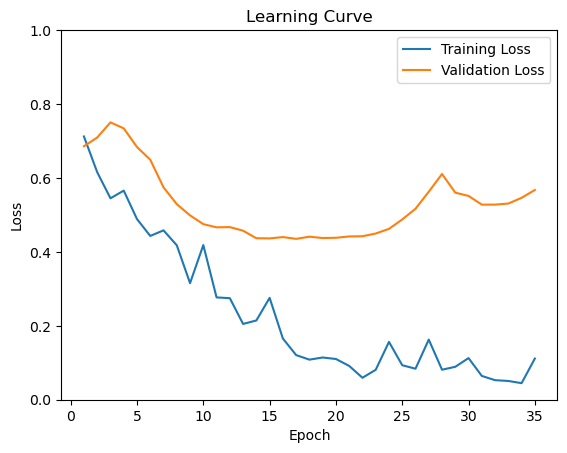

Fold 4
Accuracy Train: 0.9053061263293637. Accuracy valid: 0.8421428591012955
Recall Train: 0.8103401064872742. Recall valid: 0.800000011920929
Precision Train: 0.8775510217462267. Precision valid: 0.6785714285714286


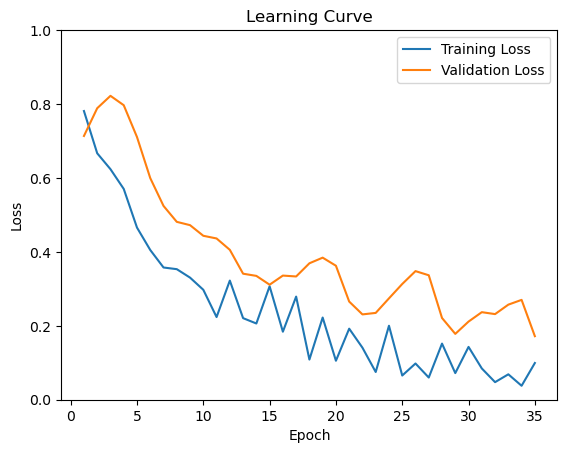

Fold 5
Accuracy Train: 0.9050000030015196. Accuracy valid: 0.7476190588303975
Recall Train: 0.8086309432983398. Recall valid: 0.6857143044471741
Precision Train: 0.8494048118591309. Precision valid: 0.8500000238418579


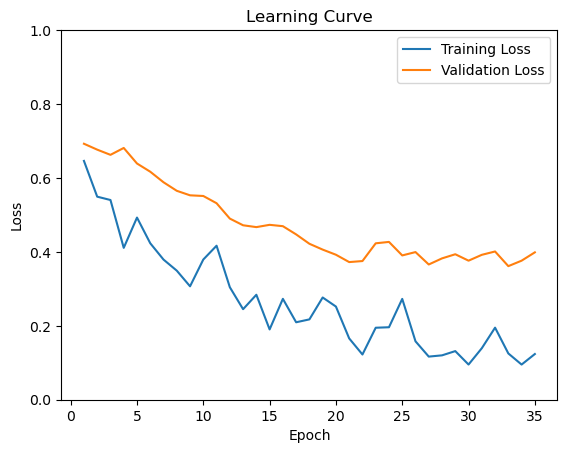

5
Fold 0: Training Loss: 0.2294093882398946, Validation Loss: 0.7643924943038396
Fold 1: Training Loss: 0.20773219695048672, Validation Loss: 0.3820913274373327
Fold 2: Training Loss: 0.23376000981245723, Validation Loss: 0.5294961356158767
Fold 3: Training Loss: 0.2447827194418226, Validation Loss: 0.3928414529987744
Fold 4: Training Loss: 0.268513588820185, Validation Loss: 0.47523606100252697
TRAIN LOSS MEDIA: 0.23683958065296923 VALID LOSS MEDIA: 0.50881149427167
TRAIN ACC MEDIA: 0.9214081664687518 VALID ACC MEDIA: 0.7898095302922383
TRAIN RECALL MEDIA: 0.8426513671875 VALID RECALL MEDIA: 0.6752380728721619
TRAIN PRECISION MEDIA: 0.8928741564069476 VALID PRECISION MEDIA: 0.7985714364051819


In [35]:
prueba_k_fold_resnet_no_pre(df_mean, 5, 35, optim.AdamW , 5, 0.00001, True, 'G')

Fold 1
Accuracy Train: 0.9542857162198242. Accuracy valid: 0.7400000069822584
Recall Train: 0.9409524202346802. Recall valid: 0.4214285612106323
Precision Train: 0.9408164024353027. Precision valid: 0.8428571428571429


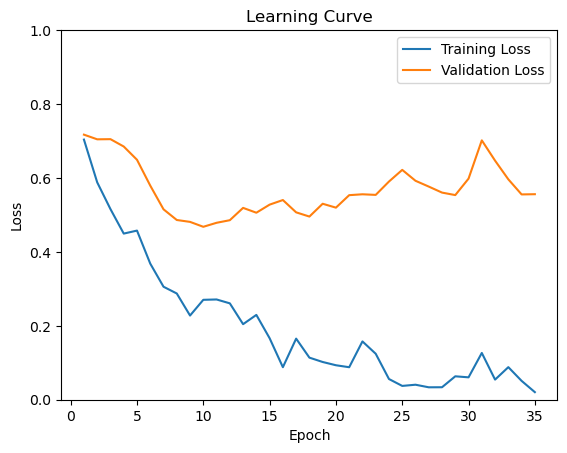

Fold 2
Accuracy Train: 0.9053061254170477. Accuracy valid: 0.7550000101327896
Recall Train: 0.7964626550674438. Recall valid: 0.5333333015441895
Precision Train: 0.8265306136437824. Precision valid: 0.8


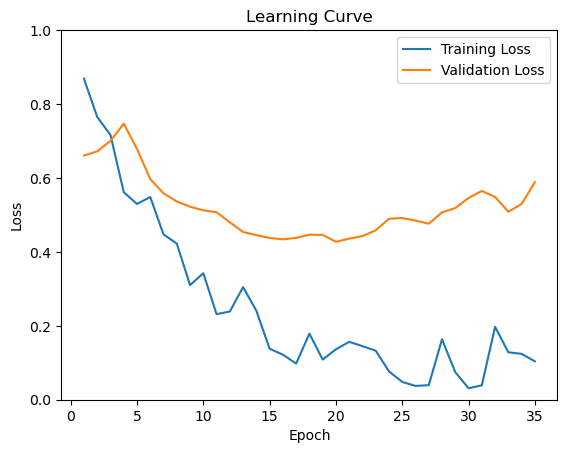

Fold 3
Accuracy Train: 0.9232653096014141. Accuracy valid: 0.8357142861400332
Recall Train: 0.9355102777481079. Recall valid: 0.7761905789375305
Precision Train: 0.8997959494590759. Precision valid: 0.9130952383790697


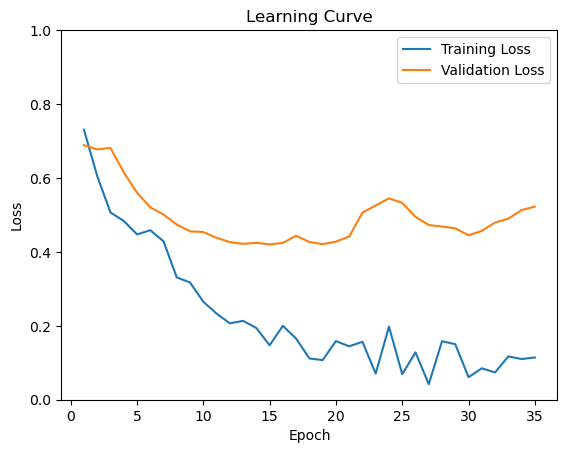

Fold 4
Accuracy Train: 0.9077551062617983. Accuracy valid: 0.802142858505249
Recall Train: 0.8002041578292847. Recall valid: 0.7666667103767395
Precision Train: 0.8700680306979588. Precision valid: 0.5928571428571429


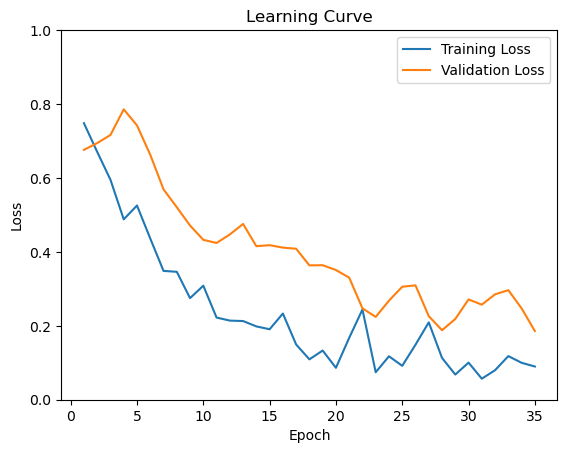

Fold 5
Accuracy Train: 0.8878571457628693. Accuracy valid: 0.7438095326934542
Recall Train: 0.8455953001976013. Recall valid: 0.8214285969734192
Precision Train: 0.8086904883384705. Precision valid: 0.834761917591095


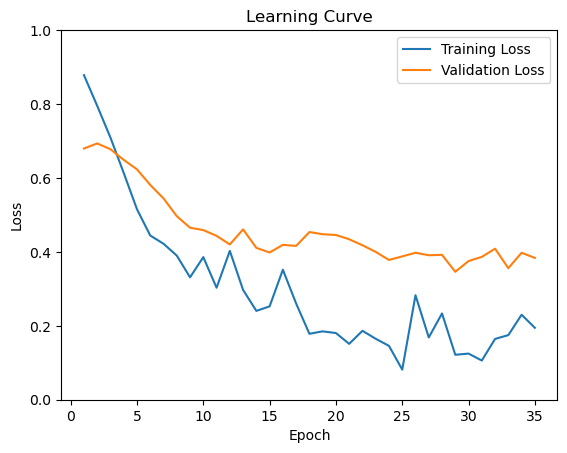

5
Fold 0: Training Loss: 0.19728186056017877, Validation Loss: 0.5689743399620056
Fold 1: Training Loss: 0.25159807338246276, Validation Loss: 0.5226024272186416
Fold 2: Training Loss: 0.2282934338918754, Validation Loss: 0.4931033850780555
Fold 3: Training Loss: 0.23629201086504117, Validation Loss: 0.4060205184987613
Fold 4: Training Loss: 0.304746270605496, Validation Loss: 0.4582207032612392
TRAIN LOSS MEDIA: 0.24364232986101078 VALID LOSS MEDIA: 0.4897842748037407
TRAIN ACC MEDIA: 0.9156938806525907 VALID ACC MEDIA: 0.7753333388907568
TRAIN RECALL MEDIA: 0.8637450337409973 VALID RECALL MEDIA: 0.6638095378875732
TRAIN PRECISION MEDIA: 0.8691802969149179 VALID PRECISION MEDIA: 0.7967142883368901


In [36]:
prueba_k_fold_resnet_no_pre(df_mean, 5, 35, optim.AdamW , 5, 0.00001, True, 'H')